# **NariSafe - Women Risk Awareness**

### **Understanding Safety Risks for Women in India**
Safety reports show that women in India face different levels of risk depending on where and when they go outside. Many safety issues happen in public places like travel stations and industrial areas, especially late at night when streets are dark and there are fewer people around to help.

### **How This Dataset Fits In**
This dataset helps us study public safety and crime patterns for women across different Indian cities. It connects official crime numbers with environmental details like street lighting, police presence, and buildings. This lets us study real-world patterns, such as why risks go up in travel areas or late at night.

### **What We Plan to Achieve with This Dataset**
Our goal is to study this data to see what causes high-risk situations. By looking at lighting, police help, and the time of day, we want to find the main patterns behind safety risks so we can better understand and predict them.

### **What You Will Find in This Notebook**
* **Data Review (EDA):** A simple look at our data to check the total number of rows and how risk levels are divided.
* **Time and Place Patterns:** Charts and notes showing how risk changes at different hours of the day and in different types of neighborhoods.
* **Environmental Factors:** A simple look at how things like streetlights and police access affect safety scores.
* **Model building and evaluation**

## Setup & Data Loading

In [129]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')

# Style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

print('Libraries loaded successfully')

Libraries loaded successfully


In [89]:
from pathlib import Path
FILE = '/content/women risk awareness - narisafe_ml_features.csv'
df = pd.read_csv(FILE)
print(f'Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
print(f'Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB')
df.head()

Dataset shape: 489,804 rows × 40 columns
Memory usage: 314.6 MB


,city,day_of_week,time_bucket,area_context,complaint_type_clean,crowd_density,latitude,longitude,is_weekend,hour,...,industrial_landuse_count_5km,retail_landuse_count_5km,education_poi_count_5km,lighting_data_available,lighting_score,police_access_score,transport_access_score,urban_density_score,complaint_severity,risk_level
0,Agra,Monday,morning,residential,abetment_to_suicide_of_women,medium,27.1767,78.0081,0,6,...,2,0,69,0,3,3,3,2,2,low
1,Agra,Monday,morning,residential,acid_attack,medium,27.1767,78.0081,0,6,...,2,0,69,0,3,3,3,2,3,medium
2,Agra,Monday,morning,residential,assault_girls_below_18,medium,27.1767,78.0081,0,6,...,2,0,69,0,3,3,3,2,2,low
3,Agra,Monday,morning,residential,assault_women_18_and_above,medium,27.1767,78.0081,0,6,...,2,0,69,0,3,3,3,2,2,medium
4,Agra,Monday,morning,residential,attempt_rape_girls_below_18,medium,27.1767,78.0081,0,6,...,2,0,69,0,3,3,3,2,3,medium


The dataset has 489,804 rows and 40 columns (about 341 MB in memory), which is large for a safety dataset with only 34 cities. The first rows already hint at the structure: consecutive rows are the same city, day, hour and area, differing only in the crime type until it reaches where the city changes.


## 2. Dataset Overview & Structure

In [90]:
# Column info
print('COLUMN TYPES SUMMARY')
print(f"\nNumerical columns:  {df.select_dtypes(include=[np.number]).shape[1]}")
print(f"Categorical columns: {df.select_dtypes(exclude=[np.number]).shape[1]}")
print(f"\nTotal columns: {df.shape[1]}")
print('\nDetailed dtypes:')
print(df.dtypes.to_string())

COLUMN TYPES SUMMARY

Numerical columns:  33
Categorical columns: 7

Total columns: 40

Detailed dtypes:
city                              object
day_of_week                       object
time_bucket                       object
area_context                      object
complaint_type_clean              object
crowd_density                     object
latitude                         float64
longitude                        float64
is_weekend                         int64
hour                               int64
complaint_type_count               int64
complaint_type_share             float64
women_crime_2021                   int64
women_crime_2022                   int64
women_crime_2023                   int64
population_lakhs                 float64
women_crime_rate_2023            float64
chargesheeting_rate_2023         float64
women_crime_growth_21_23         float64
police_station_count_5km           int64
nearest_police_station_km        float64
public_transport_count_3km        

In [91]:
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()

print('Categorical columns:')
for c in categorical_cols:
    print(f'- {c}: {df[c].nunique()} unique values')

print(f'\nNumerical columns ({len(numerical_cols)}):')
for c in numerical_cols:
    print(f'- {c}')

Categorical columns:
- city: 34 unique values
- day_of_week: 7 unique values
- time_bucket: 4 unique values
- area_context: 7 unique values
- complaint_type_clean: 42 unique values
- crowd_density: 3 unique values
- risk_level: 3 unique values

Numerical columns (33):
- latitude
- longitude
- is_weekend
- hour
- complaint_type_count
- complaint_type_share
- women_crime_2021
- women_crime_2022
- women_crime_2023
- population_lakhs
- women_crime_rate_2023
- chargesheeting_rate_2023
- women_crime_growth_21_23
- police_station_count_5km
- nearest_police_station_km
- public_transport_count_3km
- bus_stop_count_3km
- bus_station_count_3km
- railway_station_count_3km
- street_light_count_2km
- road_length_km_5km
- road_density_km_per_sqkm_5km
- commercial_landuse_count_5km
- residential_landuse_count_5km
- industrial_landuse_count_5km
- retail_landuse_count_5km
- education_poi_count_5km
- lighting_data_available
- lighting_score
- police_access_score
- transport_access_score
- urban_density_s

There are 33 numeric and 7 text columns. The 7 text or object columns consist of the 6 namely: city, weekday, time bucket, area type, crime type, crowd density plus the target variable or column `risk_level`. Only 34 cities, 42 crime types and 7 area types exist, so these categories are very very limited not variable

In [92]:
# Descriptive statistics for numerical features transposed
df[numerical_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
latitude,489804.0,21.545,6.921,8.524,17.687,22.993,26.218,34.084
longitude,489804.0,78.245,4.103,70.802,75.370,77.365,81.285,86.983
is_weekend,489804.0,0.286,0.452,0.000,0.000,0.000,1.000,1.000
hour,489804.0,14.857,5.792,6.000,9.000,15.000,21.000,23.000
complaint_type_count,489804.0,17.633,64.142,0.000,0.000,0.000,3.000,1164.000
complaint_type_share,489804.0,0.024,0.071,0.000,0.000,0.000,0.004,0.681
women_crime_2021,489804.0,678.500,415.256,104.000,367.000,529.000,939.000,1890.000
women_crime_2022,489804.0,745.265,502.084,110.000,345.000,590.000,1039.000,2366.000
women_crime_2023,489804.0,740.588,463.758,119.000,381.000,687.500,997.000,2221.000
population_lakhs,489804.0,6.641,1.422,4.600,5.500,6.200,7.400,9.800


`complaint_type_count` is extremely skewed: the mean is 17.6, the standard deviation 64.1 and the maximum 1,164, while the median is 0. The crime rate in 2023 runs from 23.1 to 300.0 per lakh (1,00,000) which is a steep rise and the chargesheeting rate from 60.0 to 97.6 percent. The year 2023 in general seems like a year with the highest showin crime rate increasing steadly from 2021 down to 2023

## 3. Missing Values

In [93]:
# Missing values check
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)

if len(missing_df) == 0:
    print('No missing values in the dataset!')
else:
    print(f'{len(missing_df)} columns with missing values:\n')
    print(missing_df.to_string())

    # Visualisation of missing values
    fig, ax = plt.subplots(figsize=(12, max(4, len(missing_df) * 0.4)))
    missing_df['Missing %'].plot(kind='barh', color='#e74c3c', ax=ax)
    ax.set_title('Missing Values by Column (%)')
    ax.set_xlabel('Missing Percentage')
    plt.tight_layout()
    plt.show()

No missing values in the dataset!


There are no known missing values, but that does not mean the data is complete or good to go for modelling. More inspection needs to be done concerning the datset

In [94]:
dims = {k: df[k].nunique() for k in ['city', 'day_of_week', 'hour', 'area_context', 'complaint_type_clean']}
expected = int(np.prod(list(dims.values())))
print(dims)
print(f'product of dimensions = {expected:,} | rows = {len(df):,} | full grid: {expected == len(df)}')
city_const = [c for c in df.columns if len(df[['city', c]].drop_duplicates()) == df.city.nunique()]
print(f'\n{len(city_const)} of {df.shape[1]} columns are constant within a city (incl. coordinates and all infrastructure counts).')

{'city': 34, 'day_of_week': 7, 'hour': 7, 'area_context': 7, 'complaint_type_clean': 42}
product of dimensions = 489,804 | rows = 489,804 | full grid: True

28 of 40 columns are constant within a city (incl. coordinates and all infrastructure counts).


The number of rows equals the product of the dimension sizes (34 x 7 x 7 x 7 x 42), so every combination of city, weekday, hour, area type and crime type appears exactly once. This seems like a synthetic dataset as it is quite impossible to have the same log of incidents across all cities

## Target Variable Analysis (`risk_level`)

Target Variable Distribution:
    medium:  287,812 (58.8%)
       low:  177,702 (36.3%)
      high:   24,290 (5.0%)


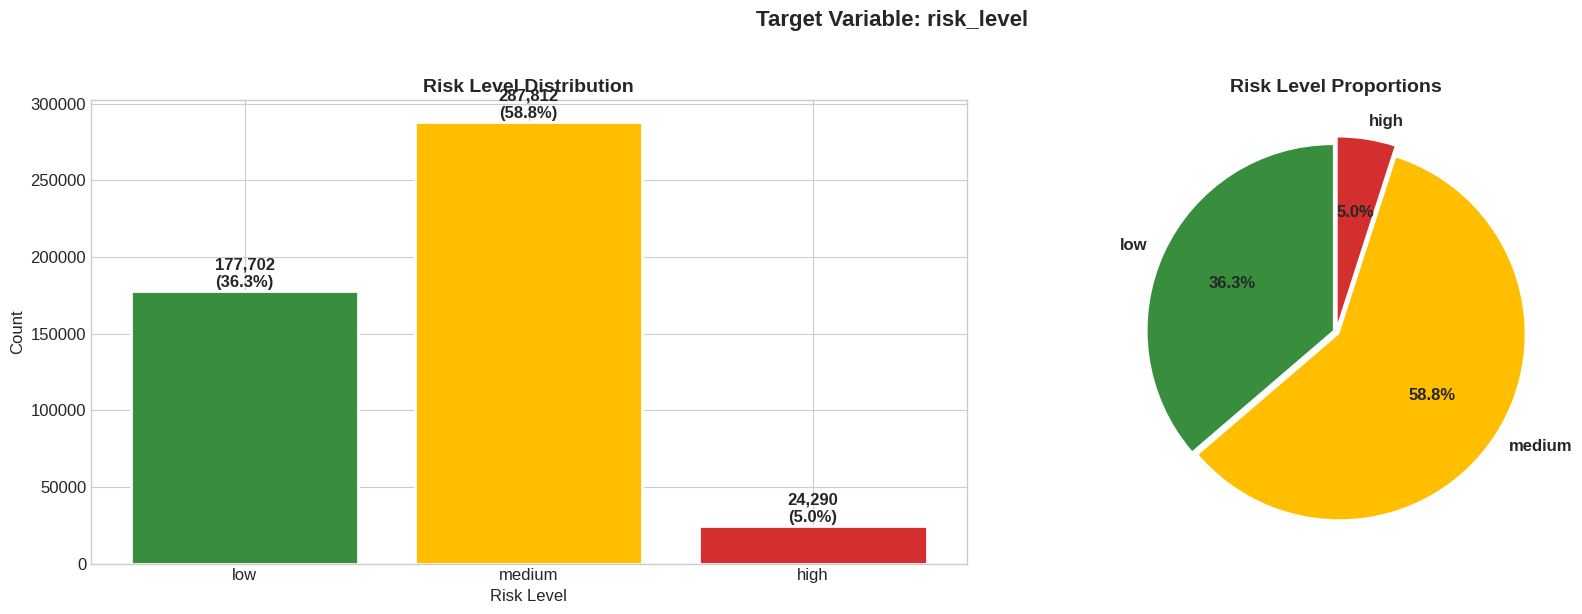

In [95]:
# Target variable distribution
target = 'risk_level'
risk_counts = df[target].value_counts()
risk_pct = df[target].value_counts(normalize=True) * 100

print('Target Variable Distribution:')
for level in risk_counts.index:
    print(f'  {level:>8}: {risk_counts[level]:>8,} ({risk_pct[level]:.1f}%)')

# Visualisation of risk_levels
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Bar chart
colors = {'low': '#388e3c', 'medium': '#ffbf00', 'high': '#d32f2f'}
order = ['low', 'medium', 'high']
bars = axes[0].bar(order, [risk_counts.get(o, 0) for o in order],
                   color=[colors.get(o, '#3498db') for o in order],
                   edgecolor='white', linewidth=2)
for bar, o in zip(bars, order):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000,
                f'{risk_counts.get(o, 0):,}\n({risk_pct.get(o, 0):.1f}%)',
                ha='center', va='bottom', fontweight='bold')
axes[0].set_title('Risk Level Distribution', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('Risk Level')

# Pie chart
axes[1].pie([risk_counts.get(o, 0) for o in order],
           labels=order, autopct='%1.1f%%',
           colors=[colors.get(o, '#3498db') for o in order],
           startangle=90, explode=(0.02, 0.02, 0.05),
           textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[1].set_title('Risk Level Proportions', fontweight='bold')

plt.suptitle('Target Variable: risk_level', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**What the output shows.** The target is imbalanced: 58.8 percent medium, 36.3 percent low and only 5.0 percent high. Plain accuracy would therefore reward a model that rarely predicts high. Macro F1 and recall on the high class are the metrics that matter here.

## Categorical Feature Analysis

In [96]:
# Every city has exactly the same number of rows
print('Distinct row counts per city:', df['city'].value_counts().unique())

Distinct row counts per city: [14406]


Every city has exactly 14,406 rows which when multilied bu the total number of cities, it leads to the toal number of rows in the datase 489, 804 rows


risk_level                low     medium       high
city                                               
Madurai             76.919339  22.886297   0.194363
Srinagar            62.730807  36.880466   0.388727
Malappuram          62.001944  37.560739   0.437318
Jamshedpur          63.459670  36.054422   0.485909
Meerut              62.439261  37.074830   0.485909
Kannur              61.856171  37.657920   0.485909
Tiruchirapalli      61.710398  37.803693   0.485909
Ludhiana            61.127308  38.338192   0.534500
Amritsar            61.710398  37.706511   0.583090
Chandigarh City     60.932945  38.435374   0.631681
Agra                47.716229  50.826045   1.457726
Nasik               46.112731  52.283771   1.603499
Thiruvananthapuram  41.836735  56.511176   1.652089
Durg-Bhilainagar    43.245870  55.053450   1.700680
Vishakhapatnam      40.864917  57.337221   1.797862
Ranchi              47.619048  50.534500   1.846453
Varanasi            42.954325  55.150632   1.895044
Vadodara    

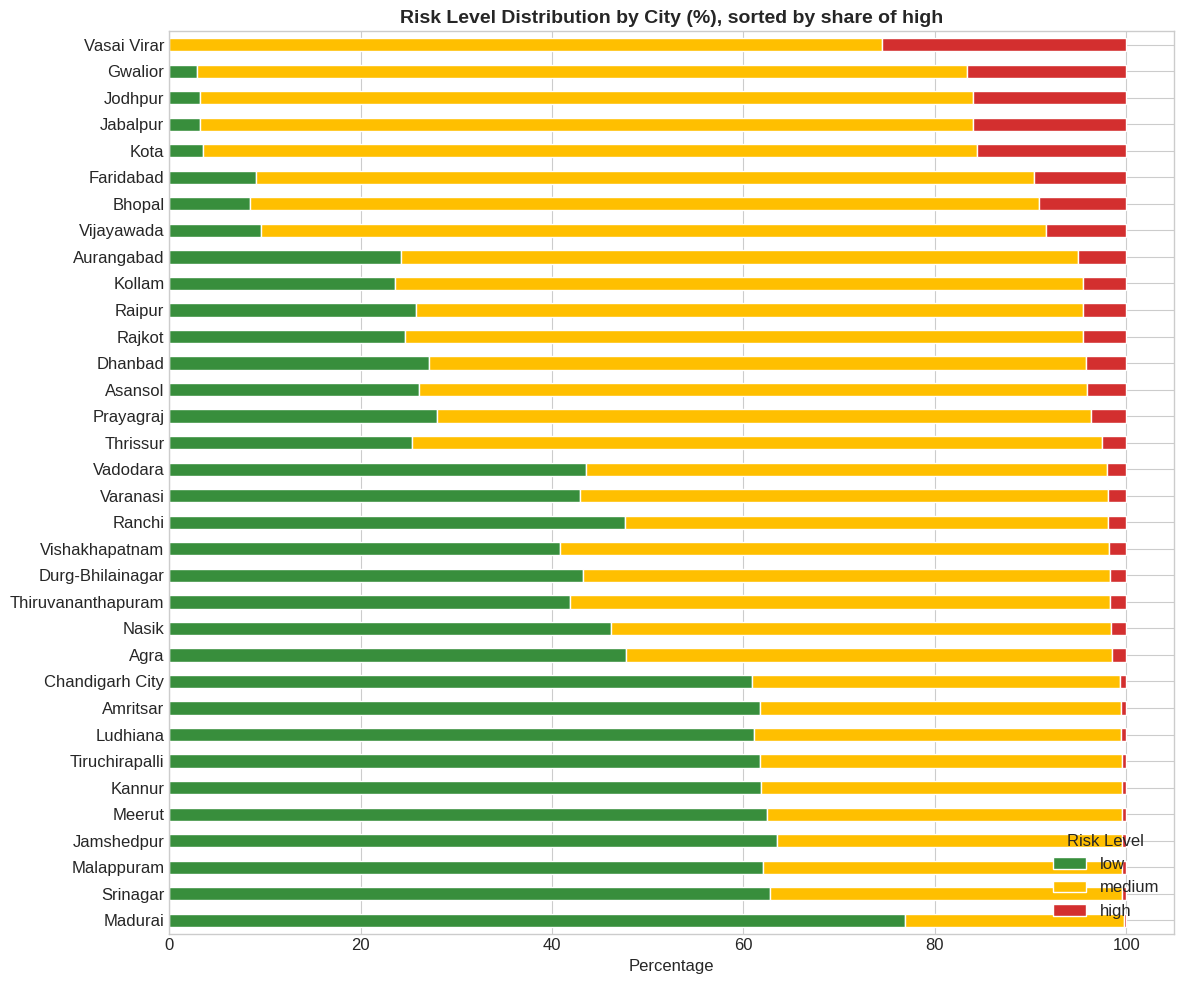

In [97]:
#evaluate risk levels across all cities
city_risk = df.groupby(['city', 'risk_level']).size().unstack(fill_value=0) #pivot by indexes
city_risk_pct = city_risk.div(city_risk.sum(axis=1), axis=0)[['low', 'medium', 'high']] * 100 #find the percentages for each risk level across the cities
city_risk_pct = city_risk_pct.sort_values(['high', 'low'], ascending=[True, False]) #rank high risk level in asecinding, low in descending
print(city_risk_pct)

fig, ax = plt.subplots(figsize=(12, 10))
city_risk_pct.plot(kind='barh', stacked=True, color=['#388e3c', '#ffbf00', '#d32f2f'], ax=ax, edgecolor='white')
ax.set_title('Risk Level Distribution by City (%), sorted by share of high', fontweight='bold')
ax.set_xlabel('Percentage'); ax.set_ylabel(''); ax.legend(title='Risk Level', loc='lower right')
plt.tight_layout(); plt.show()

Cities differ a lot in how much of their grid is labelled high. Vasai Virar has the largest high share (25.6 percent) and Madurai the smallest (0.2 percent). Gwalior, Jodhpur, Jabalpur and Kota also sit near the top. The number of rows per city is identical, these differences come entirely from the city-level inputs and a couple other things yet to be figured out at the moment

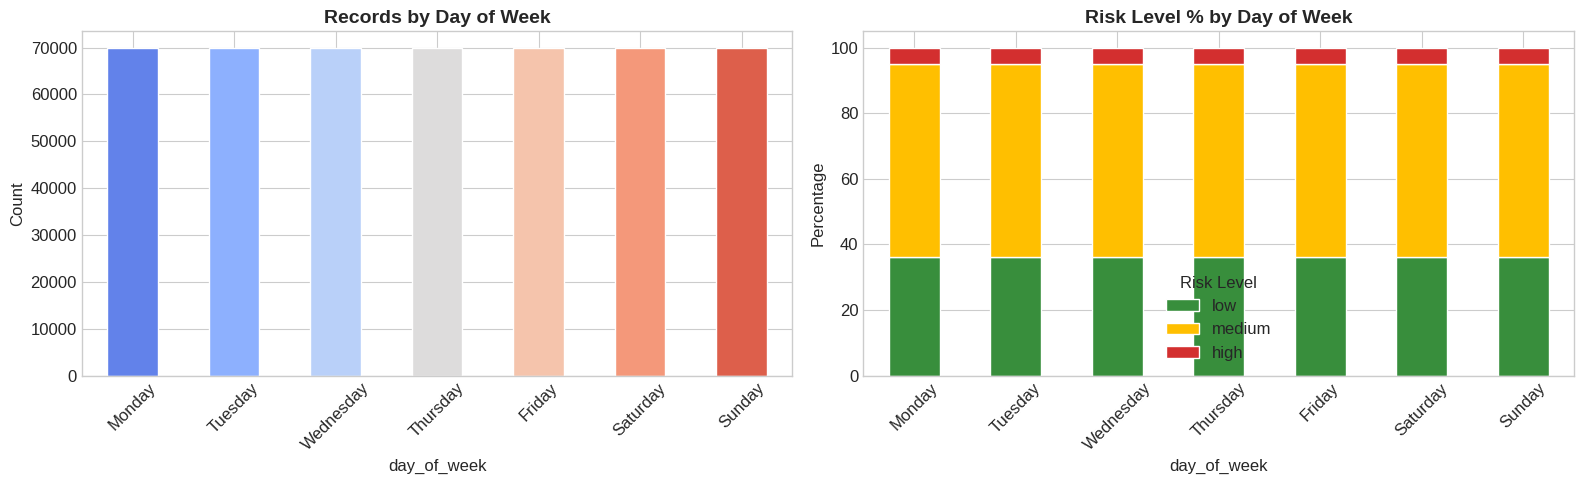

In [98]:
# Day of week analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = df['day_of_week'].value_counts().reindex(day_order)
day_counts.plot(kind='bar', color=sns.color_palette('coolwarm', 7), ax=axes[0], edgecolor='white')
axes[0].set_title('Records by Day of Week', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

# Day of week x risk level
day_risk = df.groupby(['day_of_week', 'risk_level']).size().unstack(fill_value=0)
day_risk = day_risk.reindex(day_order)
for col in ['low', 'medium', 'high']:
    if col not in day_risk.columns:
        day_risk[col] = 0
day_risk_pct = day_risk[['low', 'medium', 'high']].div(day_risk.sum(axis=1), axis=0) * 100
day_risk_pct.plot(kind='bar', stacked=True, color=['#388e3c', '#ffbf00', '#d32f2f'], ax=axes[1], edgecolor='white')
axes[1].set_title('Risk Level % by Day of Week', fontweight='bold')
axes[1].set_ylabel('Percentage')
axes[1].legend(title='Risk Level')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

There is no noticable correlation between risk levels on cetai days of the week as they all have the same risk level percentages. This could also be impacted by the even distriution of some rows across all cities in the respective days.

risk_level         low     medium       high
time_bucket                                 
afternoon    59.683874  40.196078   0.120048
evening      20.673269  72.909164   6.417567
late_night    0.650260  78.511405  20.838335
morning      46.298519  53.301321   0.400160


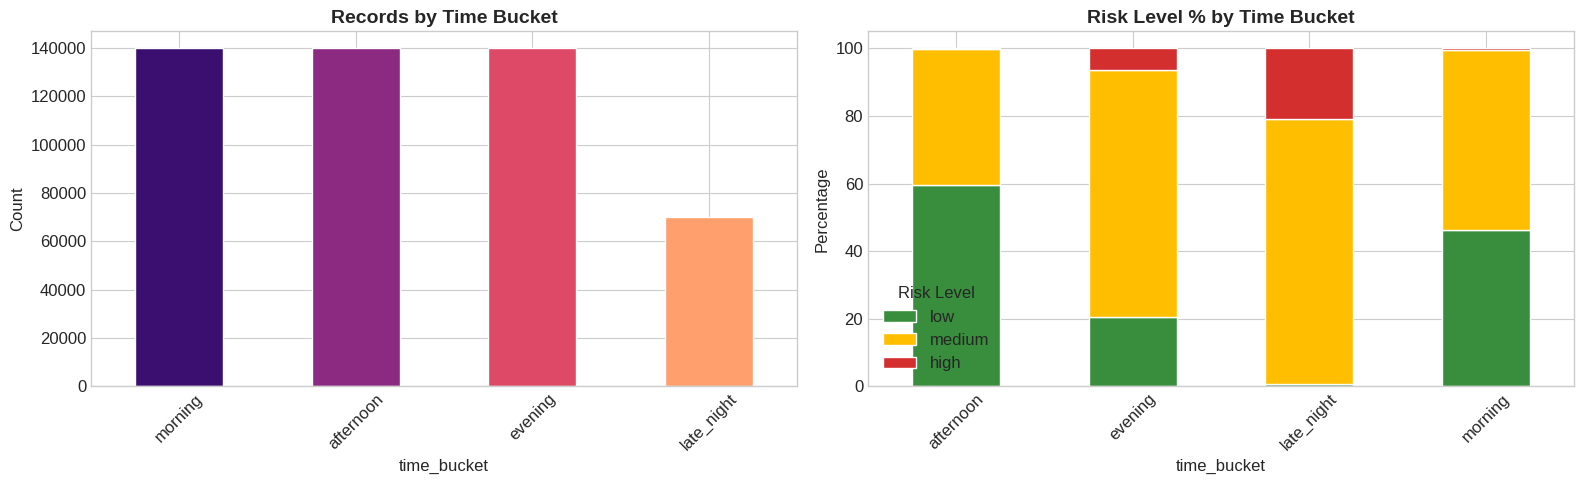

In [99]:
# Time bucket analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

time_counts = df['time_bucket'].value_counts()
time_counts.plot(kind='bar', color=sns.color_palette('magma', len(time_counts)), ax=axes[0], edgecolor='white')
axes[0].set_title('Records by Time Bucket', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

# Time bucket x risk level
time_risk = df.groupby(['time_bucket', 'risk_level']).size().unstack(fill_value=0)
for col in ['low', 'medium', 'high']:
    if col not in time_risk.columns:
        time_risk[col] = 0
time_risk_pct = time_risk[['low', 'medium', 'high']].div(time_risk.sum(axis=1), axis=0) * 100
time_risk_pct.plot(kind='bar', stacked=True, color=['#388e3c', '#ffbf00', '#d32f2f'], ax=axes[1], edgecolor='white')
axes[1].set_title('Risk Level % by Time Bucket', fontweight='bold')
axes[1].set_ylabel('Percentage')
axes[1].legend(title='Risk Level')
axes[1].tick_params(axis='x', rotation=45)

print(time_risk_pct)
plt.tight_layout()
plt.show()

Time of day (`time_bucket`) is a strong contender in predicting risk_levels. The visualisation onn time_bucket and risk_levels show that ->
* **Afternoon:** Features the highest proportion of **low risk** at approximately 60%, with the remaining ~40% classified as **medium risk**, and virtually 0% **high risk**
* **Evening:** Shows a shift where **low risk** drops to about 20%, **medium risk** expands to roughly 73%, and **high risk** emerges at around 7%
* **Late Night:** Reverses the distribution significantly, showing nearly 0% **low risk**, about 79% **medium risk**, and the peak concentration of **high risk** at roughly 21%.
* **Morning:** Displays a balanced return with **low risk** at approximately 46%, **medium risk** making up the remaining ~54%, and negligible **high risk**.

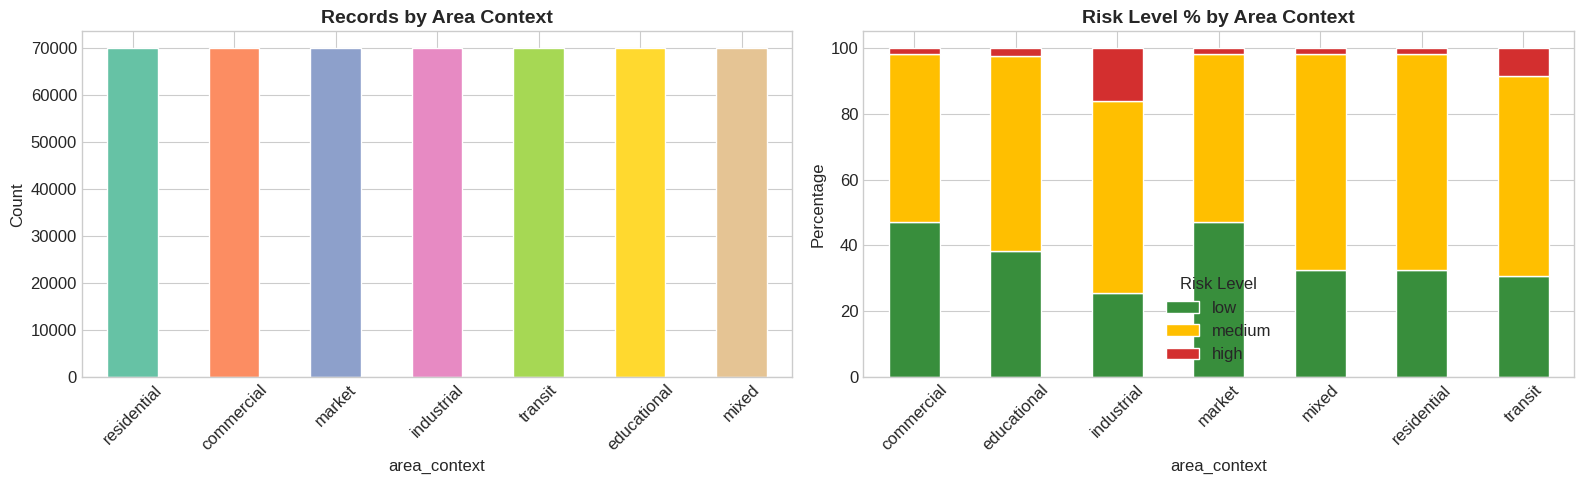

In [100]:
# Area context analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

area_counts = df['area_context'].value_counts()
area_counts.plot(kind='bar', color=sns.color_palette('Set2', len(area_counts)), ax=axes[0], edgecolor='white')
axes[0].set_title('Records by Area Context', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

# Area context x risk level
area_risk = df.groupby(['area_context', 'risk_level']).size().unstack(fill_value=0)
for col in ['low', 'medium', 'high']:
    if col not in area_risk.columns:
        area_risk[col] = 0
area_risk_pct = area_risk[['low', 'medium', 'high']].div(area_risk.sum(axis=1), axis=0) * 100
area_risk_pct.plot(kind='bar', stacked=True, color=['#388e3c', '#ffbf00', '#d32f2f'], ax=axes[1], edgecolor='white')
axes[1].set_title('Risk Level % by Area Context', fontweight='bold')
axes[1].set_ylabel('Percentage')
axes[1].legend(title='Risk Level')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Area context plays a significant role in risk distribution, with **industrial** and **transit** zones showing the most elevated high-risk concentrations, while commercial, educational, market, mixed, and residential zones display much lower high-risk proportions but distinct low-to-medium risk balances.

* **Commercial:** Features one of the highest **low risk** proportions at approximately 47%, paired with roughly 51% **medium risk** and a minimal **high risk** level of ~2%.
* **Market:** Mirrors the commercial sector closely, showing roughly 47% **low risk**, about 50% **medium risk**, and a very low **high risk** proportion of around 3 percent ish.
* **Educational:** Displays a solid **low risk** share at roughly 38%, with **medium risk** taking up about 59%, and **high risk** staying minimal at approximately 3%
* **Residential:** Holds about 32% **low risk**, roughly 65% **medium risk**, and a minimal **high risk** concentration hovering around 2% to 3%
* **Mixed:** Shows a similar distribution to residential areas, with roughly 32% **low risk**, about 65% **medium risk**, and a low-tier **high risk** level around 3%

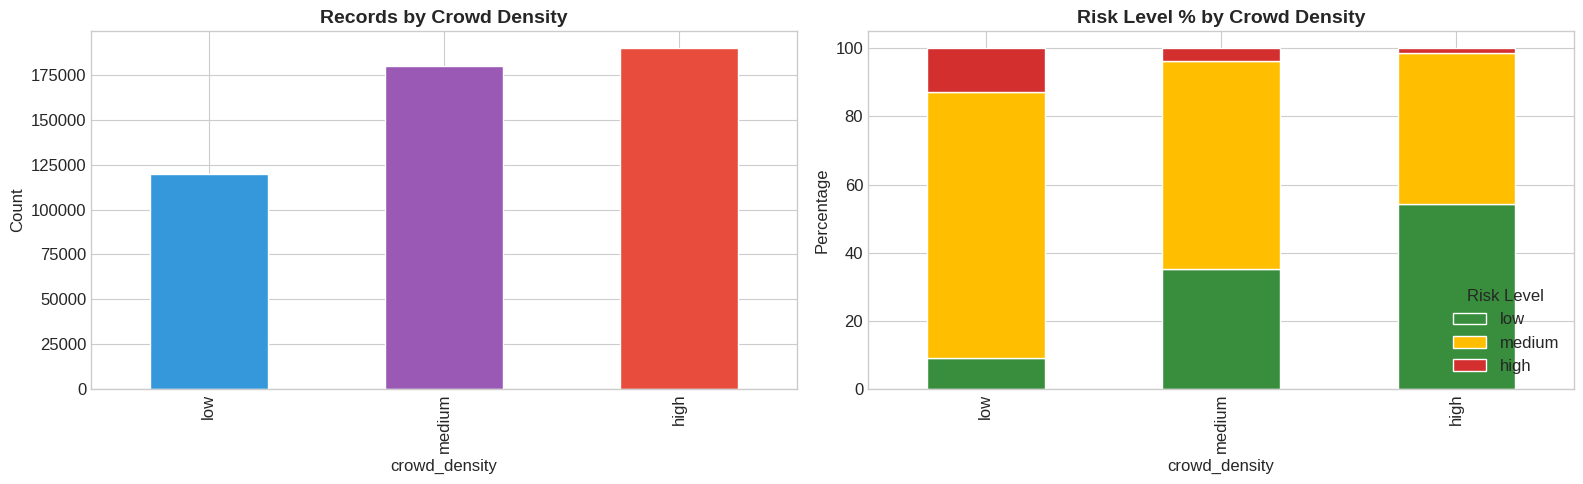

In [101]:
# Crowd density analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

density_order = ['low', 'medium', 'high']
density_counts = df['crowd_density'].value_counts().reindex(density_order)
density_counts.plot(kind='bar', color=['#3498db', '#9b59b6', '#e74c3c'], ax=axes[0], edgecolor='white')
axes[0].set_title('Records by Crowd Density', fontweight='bold')
axes[0].set_ylabel('Count')

# Crowd density x risk level
density_risk = df.groupby(['crowd_density', 'risk_level']).size().unstack(fill_value=0)
density_risk = density_risk.reindex(density_order)
for col in ['low', 'medium', 'high']:
    if col not in density_risk.columns:
        density_risk[col] = 0
density_risk_pct = density_risk[['low', 'medium', 'high']].div(density_risk.sum(axis=1), axis=0) * 100
density_risk_pct.plot(kind='bar', stacked=True, color=['#388e3c', '#ffbf00', '#d32f2f'], ax=axes[1], edgecolor='white')
axes[1].set_title('Risk Level % by Crowd Density', fontweight='bold')
axes[1].set_ylabel('Percentage')
axes[1].legend(title='Risk Level')

plt.tight_layout()
plt.show()

Number of unique complaint types: 42
Distinct row counts per complaint type: [11662]

Top 3 heads carry 64.5% of all reported cases


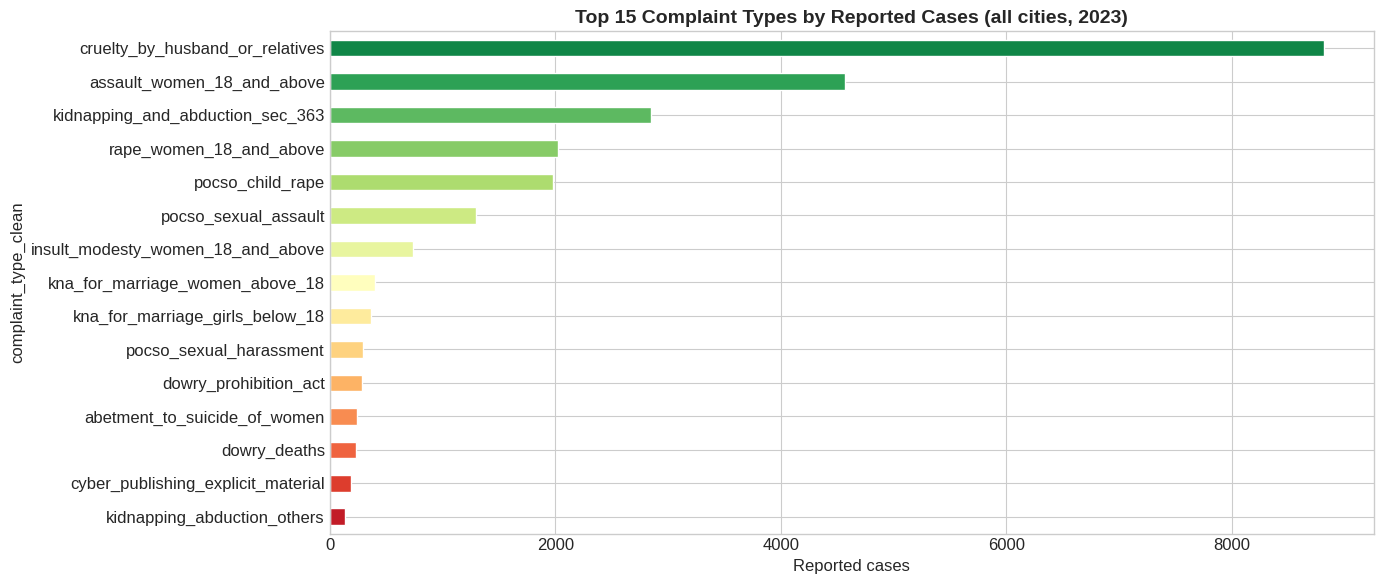

In [102]:
# Every crime head has the same number of rows in this grid, so a row-count chart is flat.
print(f"Number of unique complaint types: {df['complaint_type_clean'].nunique()}")
print('Distinct row counts per complaint type:', df['complaint_type_clean'].value_counts().unique())

cases = (df.groupby(['city', 'complaint_type_clean'])['complaint_type_count'].first()
           .groupby('complaint_type_clean').sum().sort_values(ascending=False))
print(f"\nTop 3 heads carry {cases.head(3).sum() / cases.sum():.1%} of all reported cases")

fig, ax = plt.subplots(figsize=(14, 6))
cases.head(15).plot(kind='barh', color=sns.color_palette('RdYlGn_r', 15), ax=ax, edgecolor='white')
ax.set_title('Top 15 Complaint Types by Reported Cases (all cities, 2023)', fontweight='bold')
ax.set_xlabel('Reported cases')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

Every crime category has the same number of rows (11,662), so this chart looks at the actual number of reported cases instead. Out of all the complaints, problems involving husbands or family members are by far the highest ones in the visualisation.


* **The Top Categories:**
  * `cruelty_by_husband_or_relatives` is the highest by a very large amount, showing that mistreatment by family members makes up the most reported cases.
  * `assault_women_18_and_above` is the second most reported type of crime.
  * `kidnapping_and_abduction_sec_363` is the third highest category on the list.

* **The Middle Categories:**
  * `rape_women_18_and_above` and `pocso_child_rape` show high numbers in the middle part of the chart.
  * `pocso_sexual_assault` and `insult_modesty_women_18_and_above` also show steady numbers of reported cases.

* **The Lower Categories:**
  * `kna_for_marriage_women_above_18` and `kna_for_marriage_girls_below_18` have lower numbers.
  * `pocso_sexual_harassment` and the `dowry_prohibition_act` have even fewer reported cases.
  * `abetment_to_suicide_of_women`, `dowry_deaths`, `cyber_publishing_explicit_material`, and `kidnapping_abduction_others` are at the very bottom with the lowest number of reported cases.

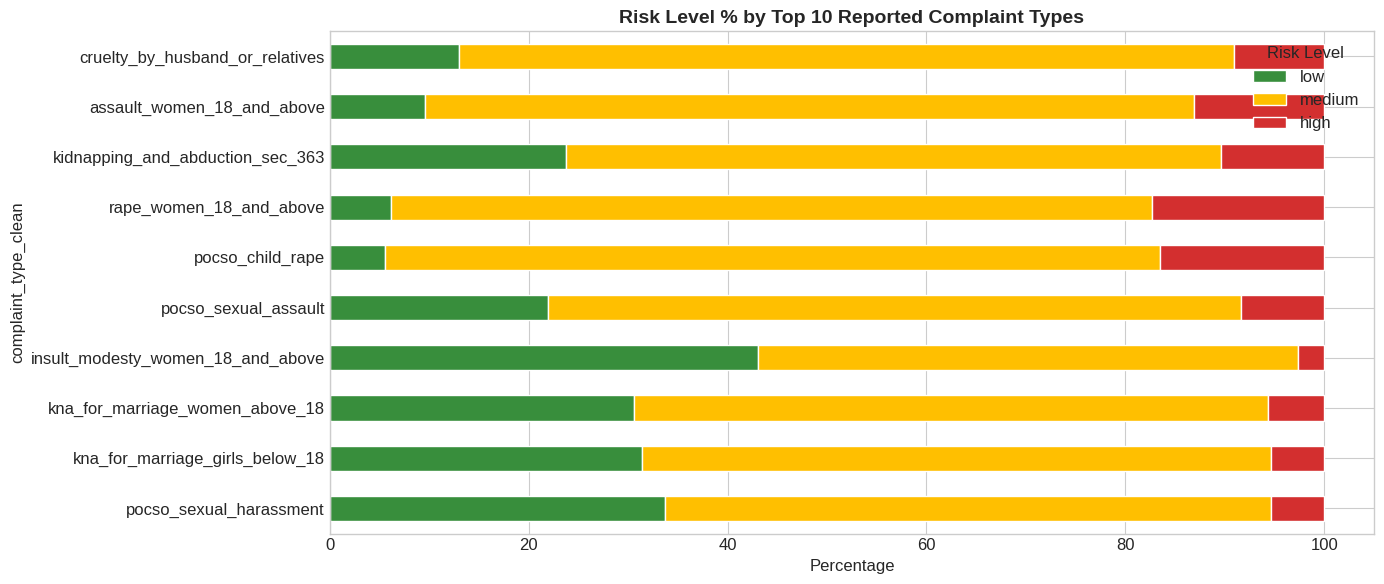

risk_level                          low  medium  high
complaint_type_clean                                 
cruelty_by_husband_or_relatives    13.0    77.9   9.1
assault_women_18_and_above          9.5    77.4  13.1
kidnapping_and_abduction_sec_363   23.7    65.9  10.4
rape_women_18_and_above             6.1    76.5  17.3
pocso_child_rape                    5.6    77.9  16.5
pocso_sexual_assault               22.0    69.7   8.3
insult_modesty_women_18_and_above  43.1    54.3   2.6
kna_for_marriage_women_above_18    30.6    63.8   5.6
kna_for_marriage_girls_below_18    31.4    63.2   5.4
pocso_sexual_harassment            33.7    60.9   5.3


In [103]:
# Risk distribution across the 10 most reported complaint types
top_10_complaints = cases.head(10).index
comp_risk = (df[df['complaint_type_clean'].isin(top_10_complaints)]
             .groupby(['complaint_type_clean', 'risk_level']).size().unstack(fill_value=0)
             .reindex(columns=['low', 'medium', 'high'], fill_value=0).reindex(top_10_complaints))
comp_risk_pct = comp_risk.div(comp_risk.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(14, 6))
comp_risk_pct.plot(kind='barh', stacked=True, color=['#388e3c', '#ffbf00', '#d32f2f'], ax=ax, edgecolor='white')
ax.set_title('Risk Level % by Top 10 Reported Complaint Types', fontweight='bold')
ax.set_xlabel('Percentage')
ax.legend(title='Risk Level')
ax.invert_yaxis()
plt.tight_layout()
plt.show()
print(comp_risk_pct.round(1).to_string())

The visualisation shows that: rape of women aged 18 and above is 17.3 percent high, child rape under POCSO 16.5 percent and assault on women 13.1 percent. Insult to modesty is only 2.6 percent. Across all heads, high is 2.0 percent for severity 1, 5.4 percent for severity 2 and 8.6 percent for severity 3, so severity is a clear driver of the label.

## Numerical Feature Analysis

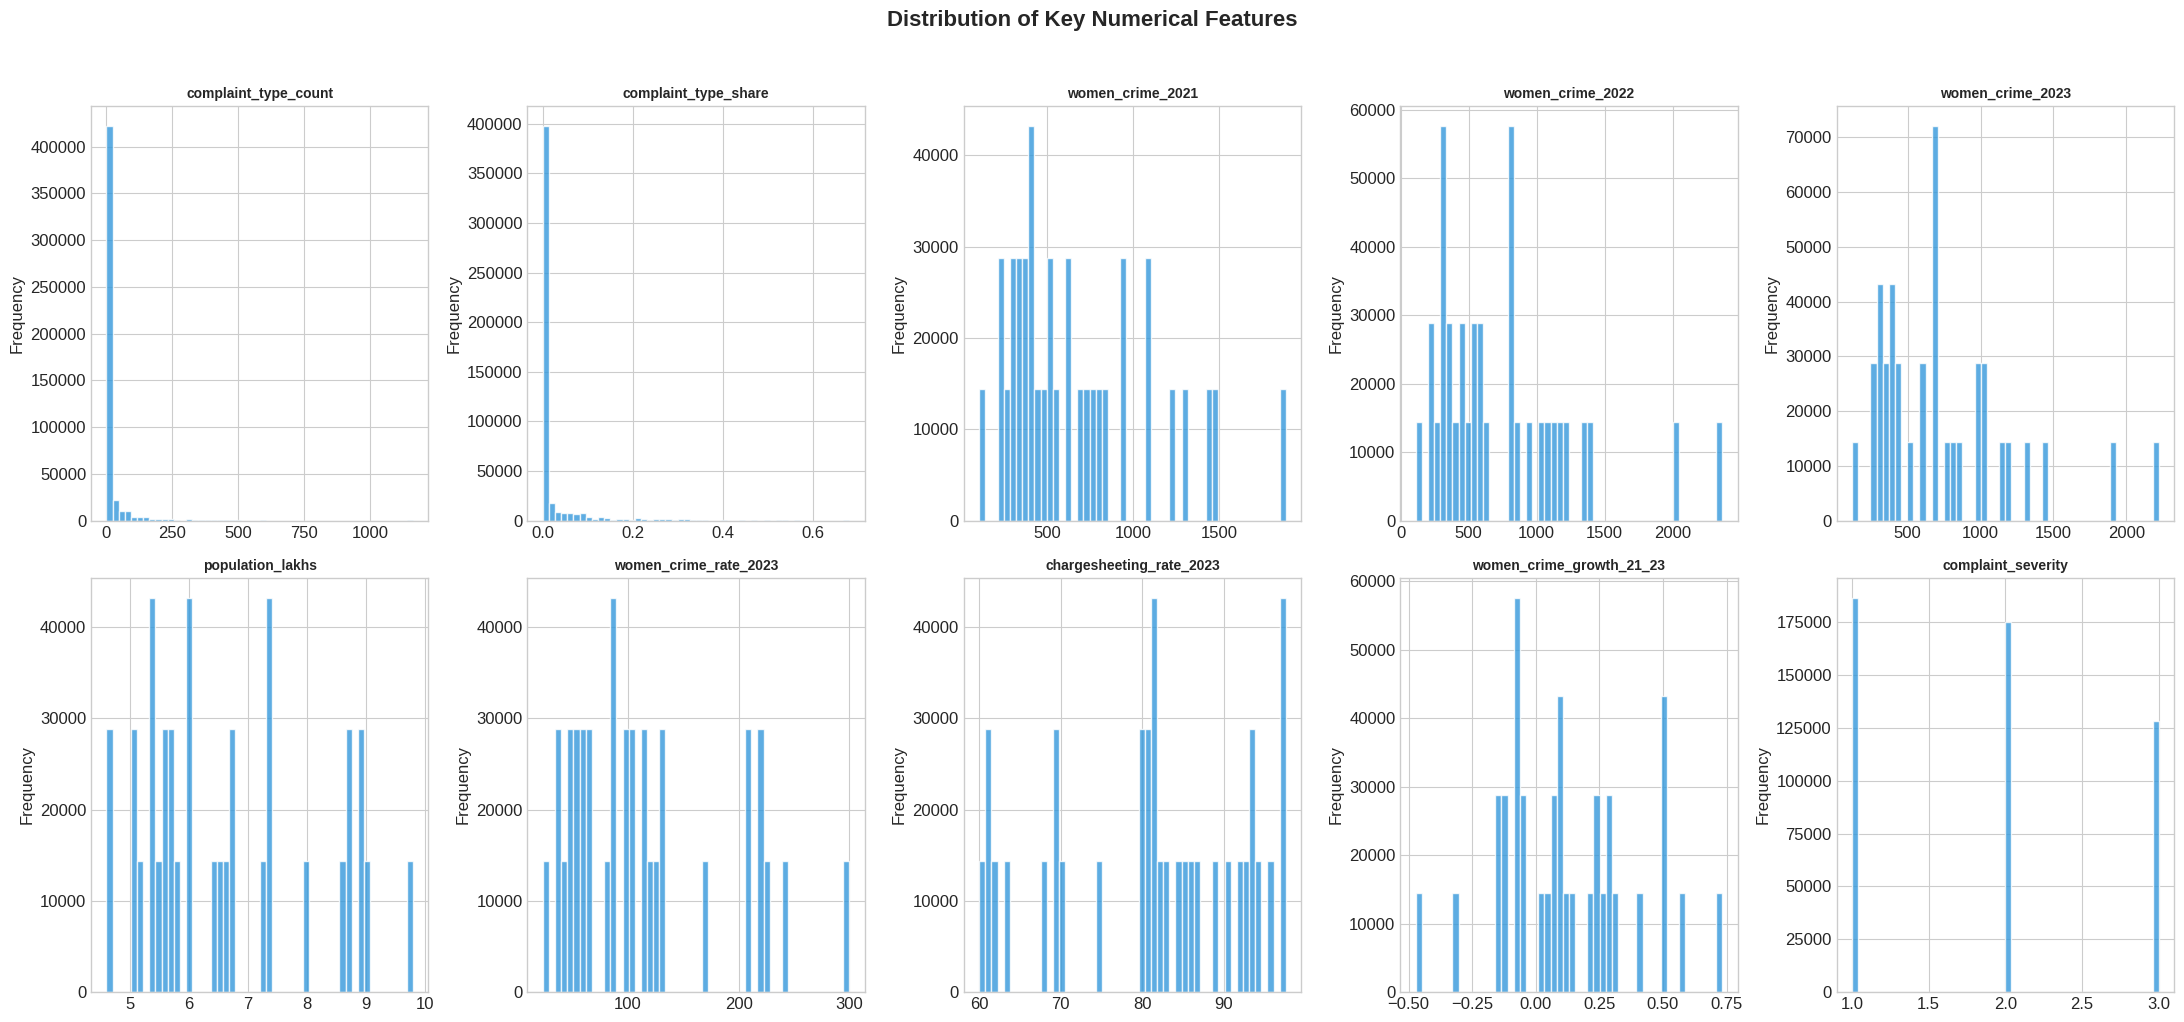

In [104]:
# Distribution of key numerical features
key_numerical = ['complaint_type_count', 'complaint_type_share', 'women_crime_2021',
                 'women_crime_2022', 'women_crime_2023', 'population_lakhs',
                 'women_crime_rate_2023', 'chargesheeting_rate_2023',
                 'women_crime_growth_21_23', 'complaint_severity']

fig, axes = plt.subplots(2, 5, figsize=(22, 10))
axes = axes.ravel()

for i, col in enumerate(key_numerical):
    if col in df.columns:
        df[col].hist(bins=50, ax=axes[i], color='#3498db', edgecolor='white', alpha=0.8)
        axes[i].set_title(col, fontweight='bold', fontsize=10)
        axes[i].set_ylabel('Frequency')

plt.suptitle('Distribution of Key Numerical Features', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

`complaint_type_count` and `complaint_type_share` is heavily right-skewed.

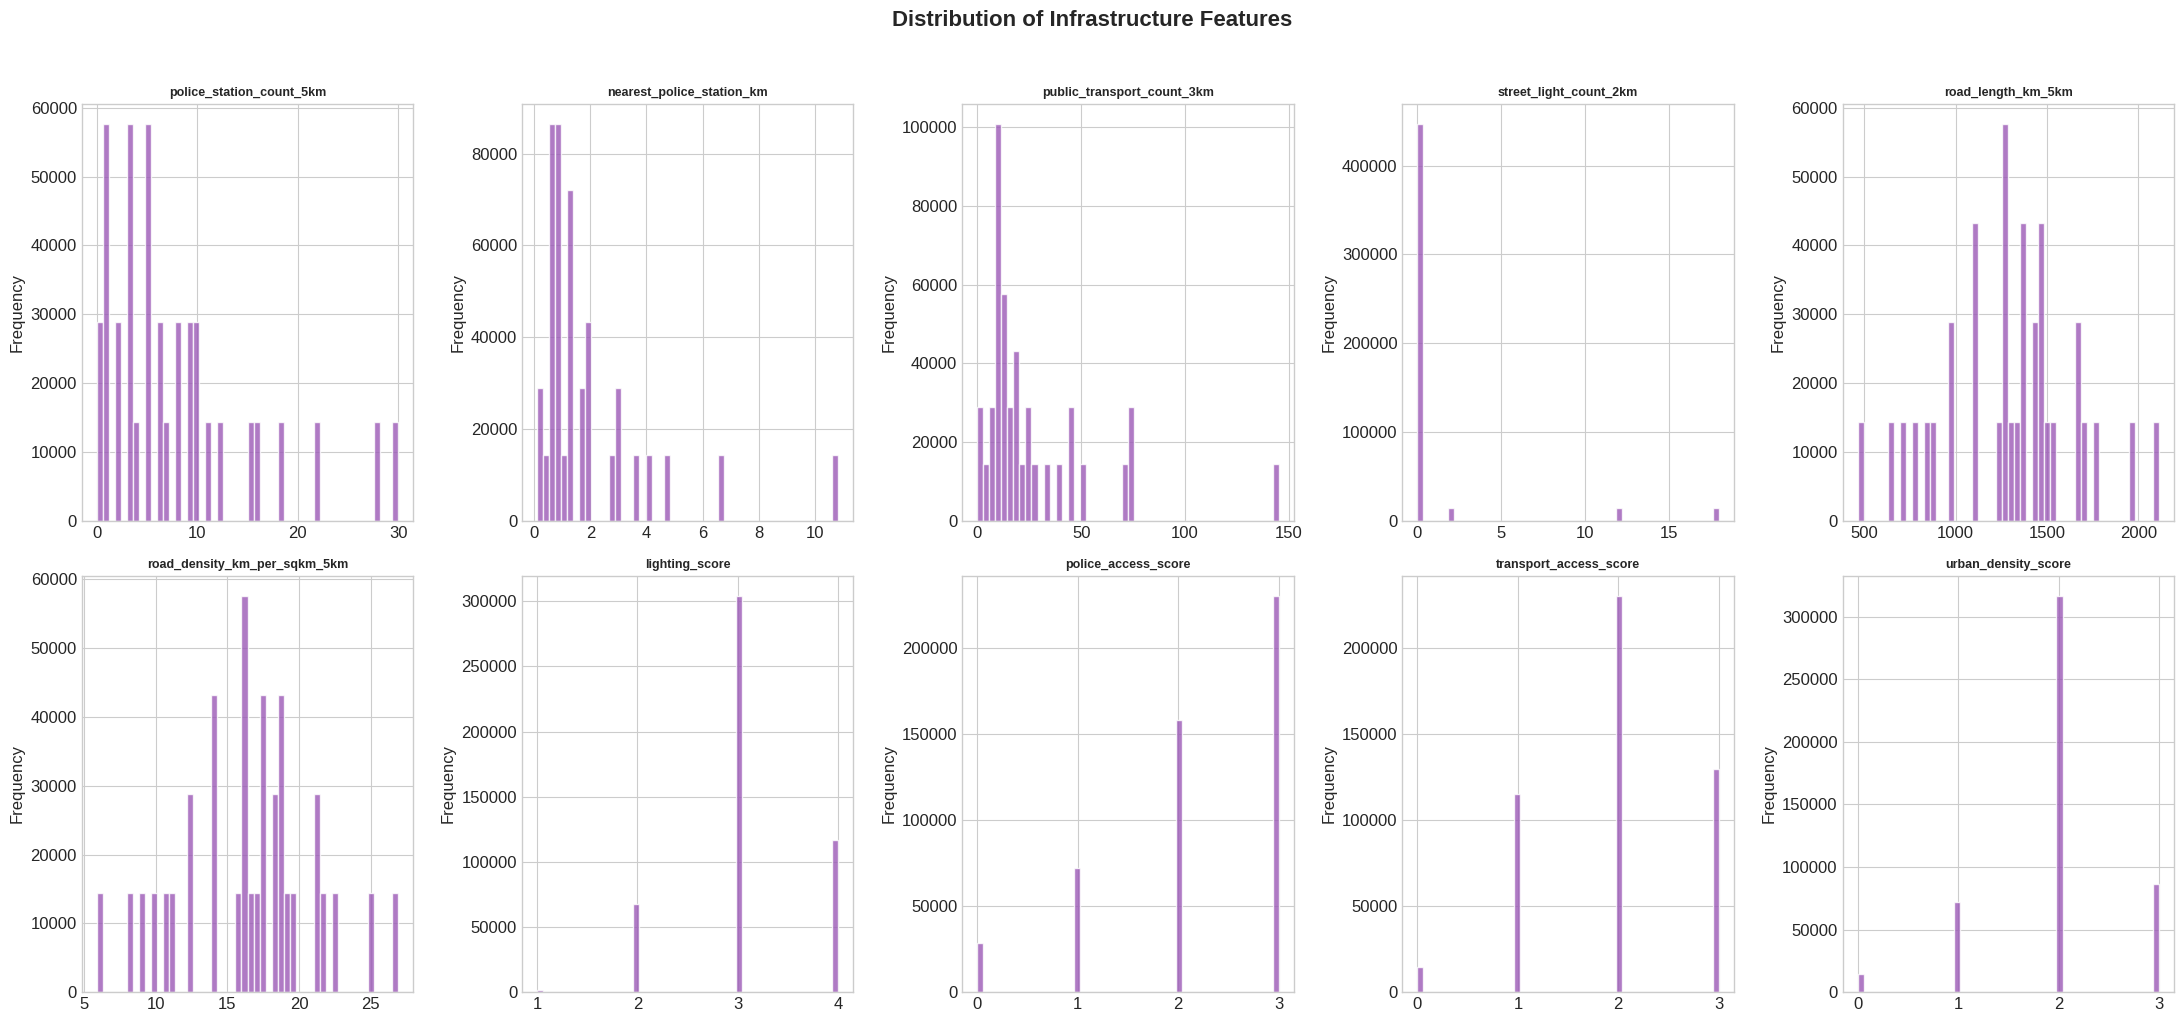

In [105]:
# Infrastructure-related feature distributions
infra_cols = ['police_station_count_5km', 'nearest_police_station_km',
              'public_transport_count_3km', 'street_light_count_2km',
              'road_length_km_5km', 'road_density_km_per_sqkm_5km',
              'lighting_score', 'police_access_score',
              'transport_access_score', 'urban_density_score']

fig, axes = plt.subplots(2, 5, figsize=(22, 10))
axes = axes.ravel()

for i, col in enumerate(infra_cols):
    if col in df.columns:
        df[col].hist(bins=50, ax=axes[i], color='#9b59b6', edgecolor='white', alpha=0.8)
        axes[i].set_title(col, fontweight='bold', fontsize=9)
        axes[i].set_ylabel('Frequency')

plt.suptitle('Distribution of Infrastructure Features', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Infrastructure is highly uneven. Street-light counts are zero in 31 of 34 cities and bus-stop counts are zero in 7. The nearest police station is a median of 1.26 km away but up to 10.85 km in the worst city. These columns describe city centres, so they cannot distinguish one area type from another within a city.

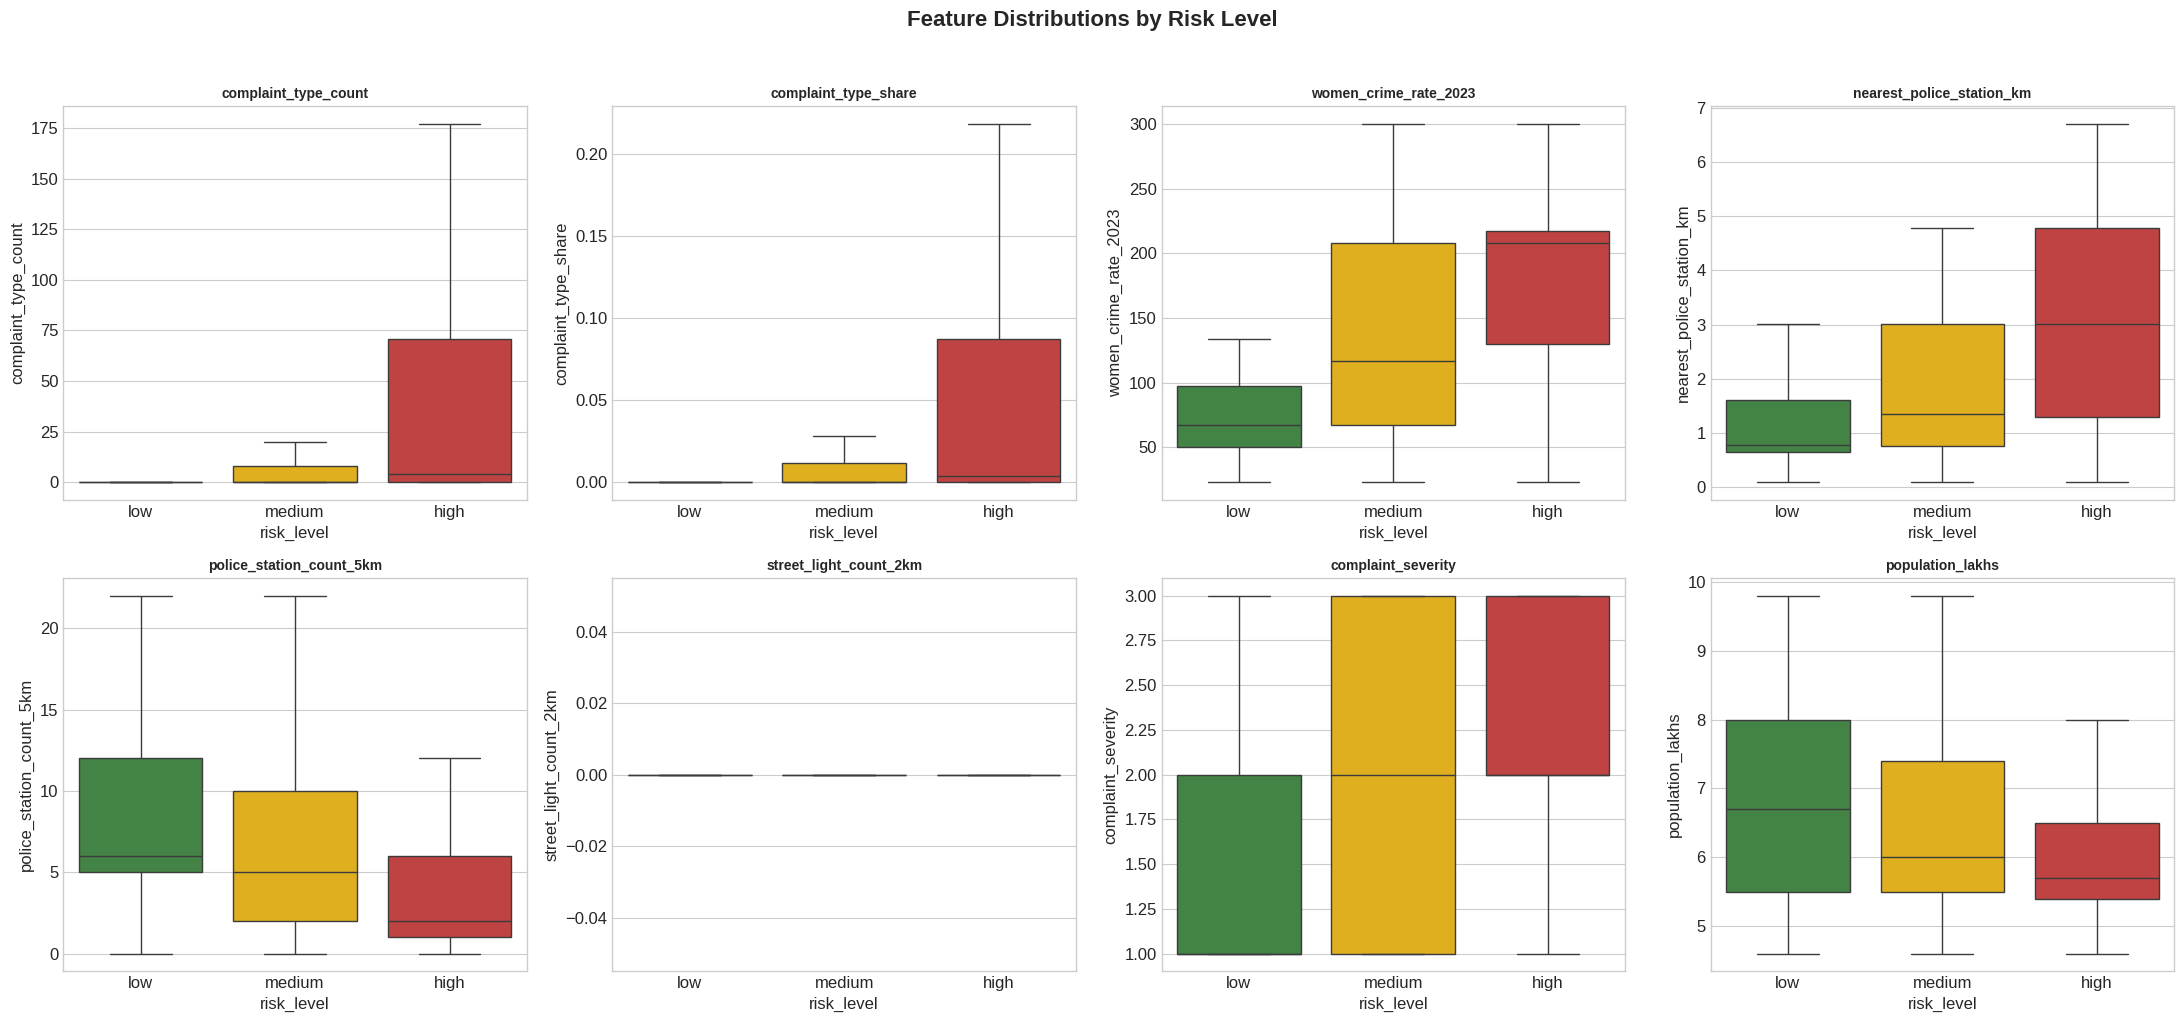

In [106]:
# Box plots of key features by risk level
box_features = ['complaint_type_count', 'complaint_type_share', 'women_crime_rate_2023',
                'nearest_police_station_km', 'police_station_count_5km',
                'street_light_count_2km', 'complaint_severity', 'population_lakhs']

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.ravel()

risk_order = ['low', 'medium', 'high']
palette = {'low': '#388e3c', 'medium': '#ffbf00', 'high': '#d32f2f'}

for i, col in enumerate(box_features):
    if col in df.columns:
        sns.boxplot(data=df, x='risk_level', y=col, order=risk_order,
                   palette=palette, ax=axes[i], showfliers=False)
        axes[i].set_title(f'{col}', fontweight='bold', fontsize=10)

plt.suptitle('Feature Distributions by Risk Level', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

 Higher-risk rows come from cities with higher crime rates and weaker police access. Median crime rate is 67.4 for low, 116.6 for medium and 208.3 for high risk. Median distance to the nearest police station is 0.77, 1.34 and 3.02 km, and the median number of police stations within 5 km falls from 6 to 5 to 2. Median complaint count is 0 for low and medium and 4 for high. Street lights show no separation because the median is zero in every group.

## Correlation Analysis

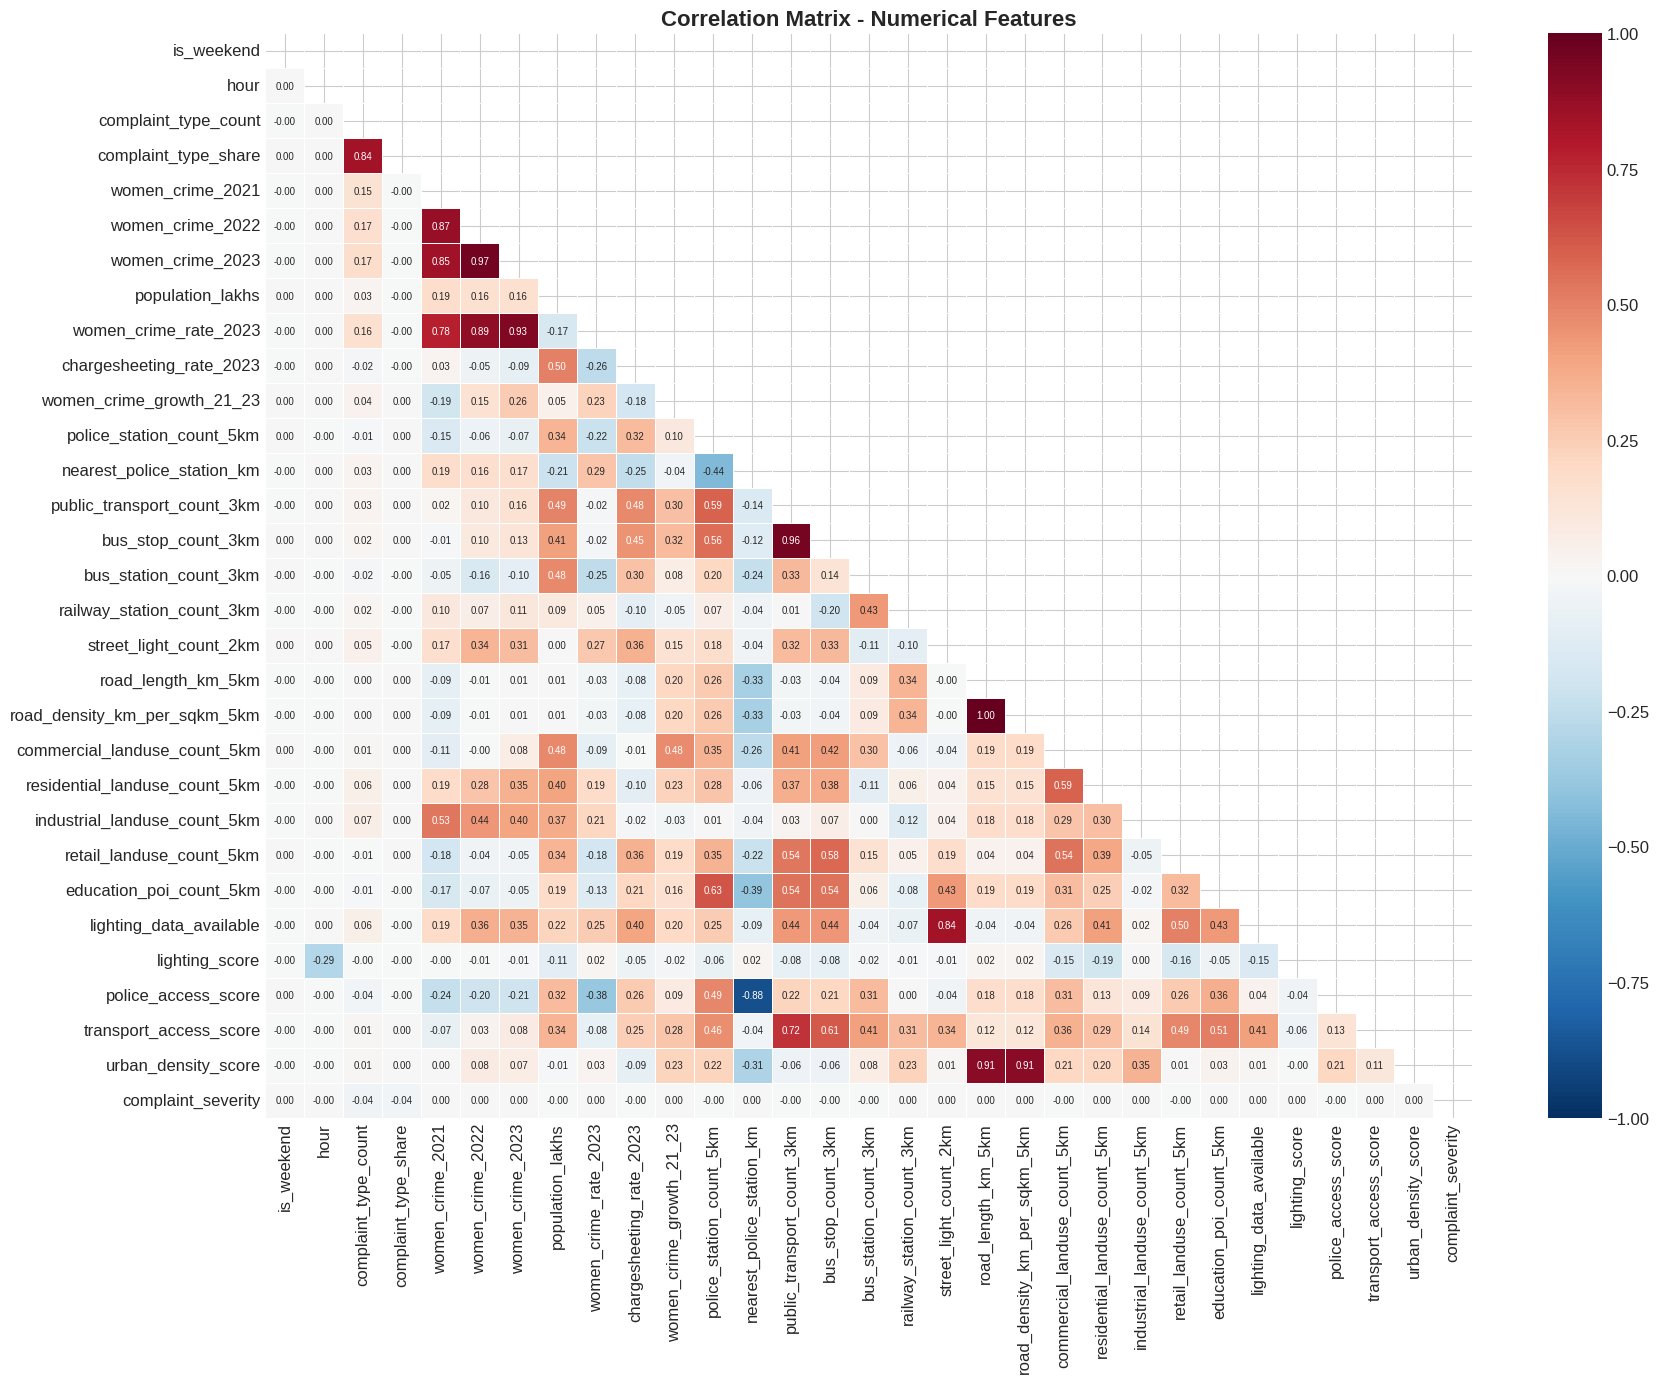

In [107]:
# Correlation heatmap for numerical features
corr_cols = [c for c in numerical_cols if c not in ['latitude', 'longitude']]
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(18, 14))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
           center=0, vmin=-1, vmax=1, ax=ax,
           annot_kws={'size': 7}, linewidths=0.5)
ax.set_title('Correlation Matrix - Numerical Features', fontweight='bold', fontsize=16)
plt.tight_layout()
plt.show()

The heatmap shows blocks of redundant columns: the three yearly crime counts correlate at 0.85 to 0.97, road length and road density are perfectly correlated, and transport and bus-stop counts are almost the same signal. About 80 percent of the 465 column pairs have an absolute correlation below 0.3, so most columns carry separate information.

Top features by |Spearman| with risk_level:

lighting_score              -0.454
women_crime_rate_2023        0.406
women_crime_2023             0.377
hour                         0.372
women_crime_2022             0.352
women_crime_2021             0.329
complaint_type_count         0.313
nearest_police_station_km    0.306
complaint_type_share         0.300
police_access_score         -0.286
complaint_severity           0.271
police_station_count_5km    -0.217
bus_station_count_3km       -0.216
education_poi_count_5km     -0.189
retail_landuse_count_5km    -0.183

Note: city-level columns take only 34 distinct values, so their correlations rest on 34 cities, not 490k rows.


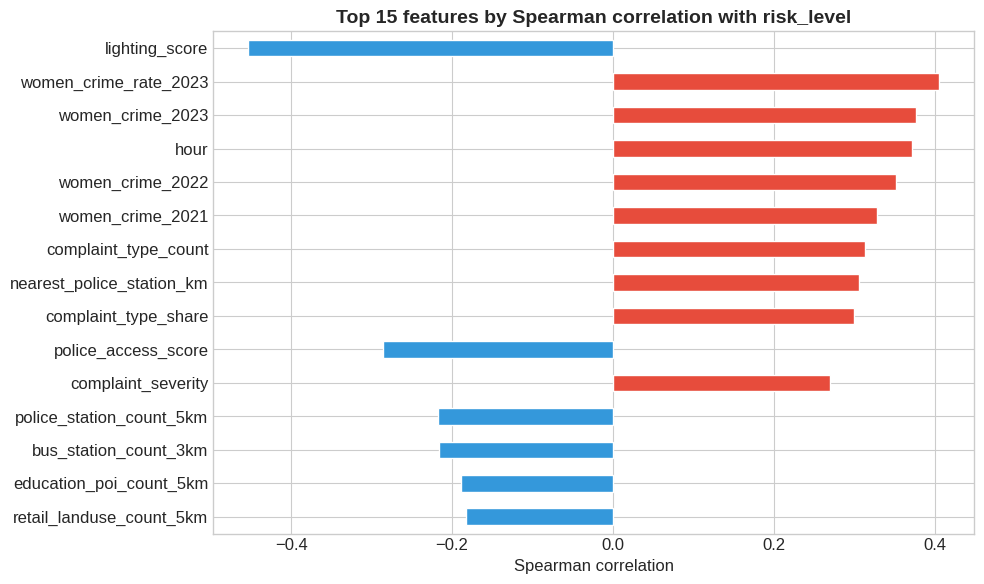

In [108]:
# Spearman correlation of every numeric column with the label (low=1, medium=2, high=3)
df['risk_numeric'] = df['risk_level'].map({'low': 1, 'medium': 2, 'high': 3})
risk_corr = df[corr_cols].corrwith(df['risk_numeric'], method='spearman').dropna()
top = risk_corr.reindex(risk_corr.abs().sort_values(ascending=False).index).head(15)
print('Top features by |Spearman| with risk_level:\n')
print(top.round(3).to_string())
print('\nNote: city-level columns take only 34 distinct values, so their correlations rest on 34 cities, not 490k rows.')

fig, ax = plt.subplots(figsize=(10, 6))
top.iloc[::-1].plot(kind='barh', color=['#e74c3c' if v > 0 else '#3498db' for v in top.iloc[::-1]], ax=ax, edgecolor='white')
ax.set_title('Top 15 features by Spearman correlation with risk_level', fontweight='bold')
ax.set_xlabel('Spearman correlation'); plt.tight_layout(); plt.show()

Most of the columns here are not strongly correlated. With risk levels with many falling below 0.5 showing weak sperman corrleation. Lightning_score seems to have a negatuve correlation coefficient. Meaning as one value decresed, the other increased displaying an inversely proportional. So, as the number of street lights in a particular area incresed, the risk levels of assaults decreased and vice versa.

In [109]:
# Identify highly correlated feature pairs (potential multicollinearity)
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.8:
            high_corr_pairs.append({
                'Feature 1': corr_matrix.columns[i],
                'Feature 2': corr_matrix.columns[j],
                'Correlation': round(corr_matrix.iloc[i, j], 3)
            })

if high_corr_pairs:
    print('Highly Correlated Feature Pairs (|r| > 0.8):\n')
    hc_df = pd.DataFrame(high_corr_pairs).sort_values('Correlation', key=abs, ascending=False)
    print(hc_df.to_string(index=False))
else:
    print('No highly correlated feature pairs found (threshold |r| > 0.8)')

Highly Correlated Feature Pairs (|r| > 0.8):

                   Feature 1                    Feature 2  Correlation
          road_length_km_5km road_density_km_per_sqkm_5km        1.000
            women_crime_2022             women_crime_2023        0.966
  public_transport_count_3km           bus_stop_count_3km        0.959
            women_crime_2023        women_crime_rate_2023        0.926
road_density_km_per_sqkm_5km          urban_density_score        0.905
          road_length_km_5km          urban_density_score        0.905
            women_crime_2022        women_crime_rate_2023        0.885
   nearest_police_station_km          police_access_score       -0.879
            women_crime_2021             women_crime_2022        0.873
            women_crime_2021             women_crime_2023        0.850
      street_light_count_2km      lighting_data_available        0.839
        complaint_type_count         complaint_type_share        0.836


## Crime Trends & Geographic Analysis

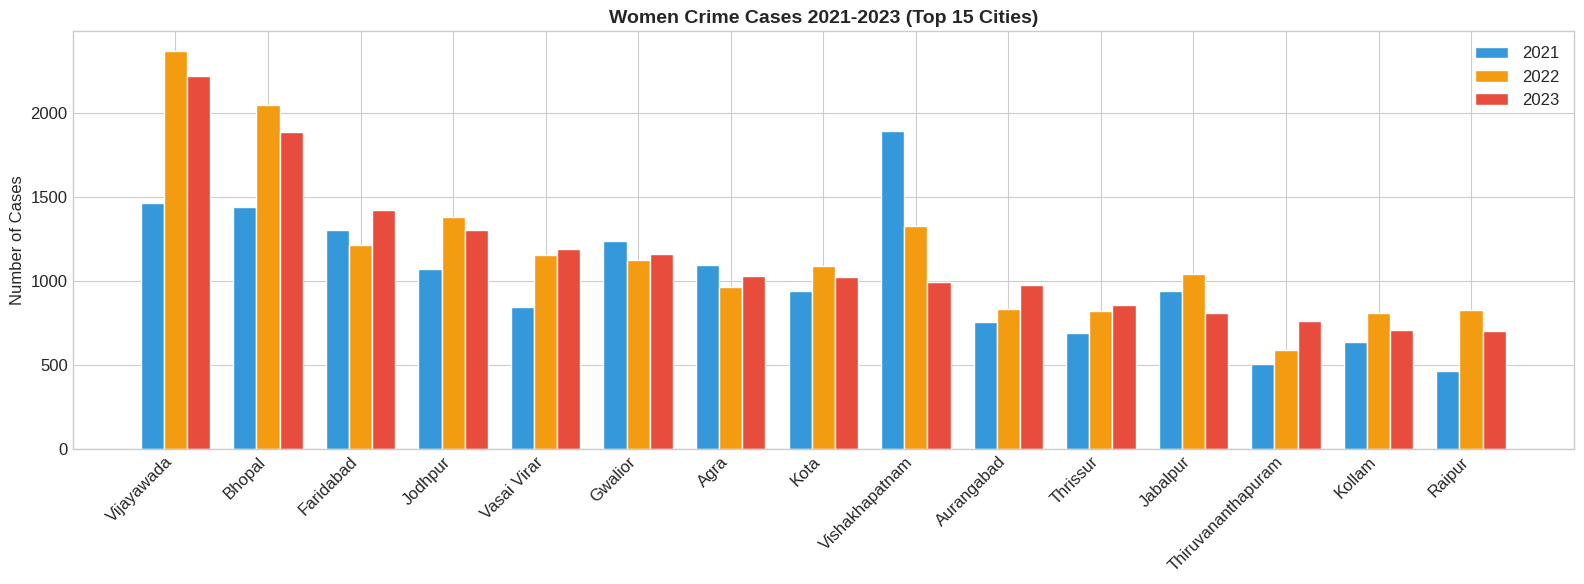

In [110]:
# Crime trends 2021-2023 by city
crime_cols = ['women_crime_2021', 'women_crime_2022', 'women_crime_2023']
city_crime = df.groupby('city')[crime_cols].first().sort_values('women_crime_2023', ascending=False)

fig, ax = plt.subplots(figsize=(16, 6))
top_crime_cities = city_crime.head(15)
x = np.arange(len(top_crime_cities))
width = 0.25

bars1 = ax.bar(x - width, top_crime_cities['women_crime_2021'], width, label='2021', color='#3498db', edgecolor='white')
bars2 = ax.bar(x, top_crime_cities['women_crime_2022'], width, label='2022', color='#f39c12', edgecolor='white')
bars3 = ax.bar(x + width, top_crime_cities['women_crime_2023'], width, label='2023', color='#e74c3c', edgecolor='white')

ax.set_xticks(x)
ax.set_xticklabels(top_crime_cities.index, rotation=45, ha='right')
ax.set_title('Women Crime Cases 2021-2023 (Top 15 Cities)', fontweight='bold', fontsize=14)
ax.set_ylabel('Number of Cases')
ax.legend()
plt.tight_layout()
plt.show()

The count in 2023 the top cities are Vijayawada (2,221), Bhopal (1,886), Faridabad (1,424), Jodhpur (1,304) and Vasai Virar (1,191). Raw counts partly reflect city size, which is why the per-lakh rate is the better comparison. By rate, Vijayawada is also highest (300.0) and Tiruchirapalli lowest (23.1).

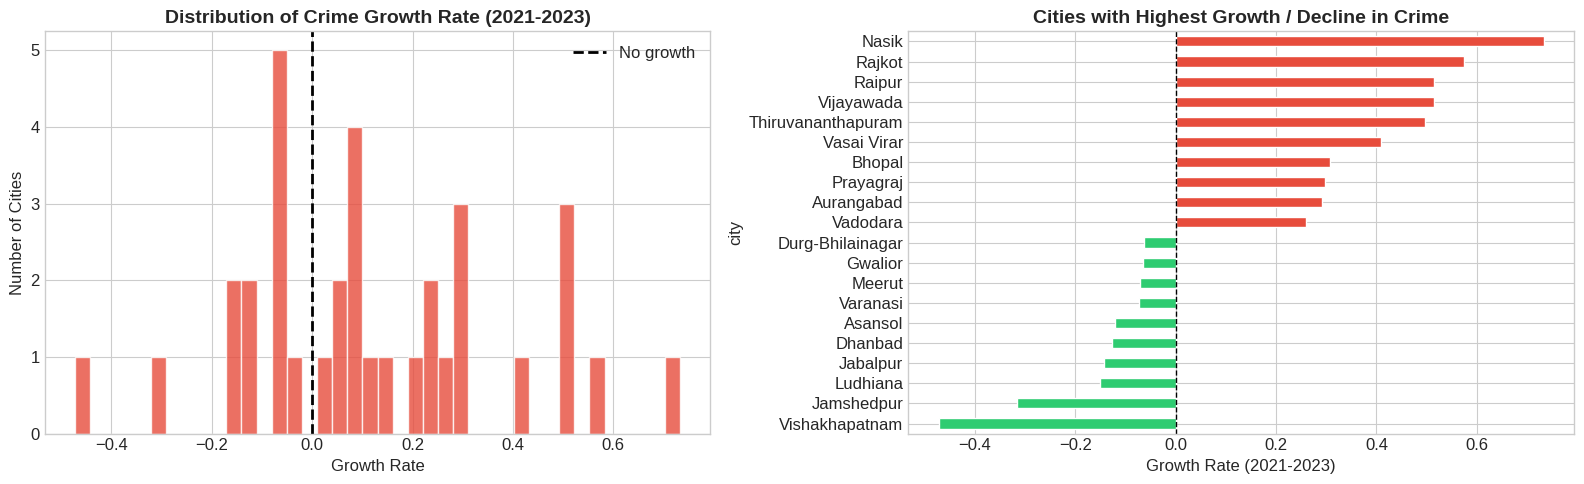

In [111]:
# Crime growth rate distribution
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

growth_by_city = df.groupby('city')['women_crime_growth_21_23'].first()
growth_by_city.hist(bins=40, ax=axes[0], color='#e74c3c', edgecolor='white', alpha=0.8)
axes[0].axvline(x=0, color='black', linestyle='--', linewidth=2, label='No growth')
axes[0].set_title('Distribution of Crime Growth Rate (2021-2023)', fontweight='bold')
axes[0].set_xlabel('Growth Rate')
axes[0].set_ylabel('Number of Cities')
axes[0].legend()

# Top growing and declining cities
growth_sorted = growth_by_city.sort_values()
top_decline = growth_sorted.head(10)
top_growth = growth_sorted.tail(10)
combined = pd.concat([top_decline, top_growth])
colors_growth = ['#2ecc71' if v < 0 else '#e74c3c' for v in combined.values]
combined.plot(kind='barh', ax=axes[1], color=colors_growth, edgecolor='white')
axes[1].axvline(x=0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Cities with Highest Growth / Decline in Crime', fontweight='bold')
axes[1].set_xlabel('Growth Rate (2021-2023)')

plt.tight_layout()
plt.show()

Between 2021 and 2023 reported crime rose in 22 cities and fell in 12, with a median rise of 9 percent. The largest rises were in Nasik (73 percent), Rajkot (57 percent) and Raipur (52 percent). The largest falls were in Vishakhapatnam (47 percent), Jamshedpur (32 percent) and Ludhiana (15 percent). A fall in registered cases can reflect changes in reporting as much as in real safety.

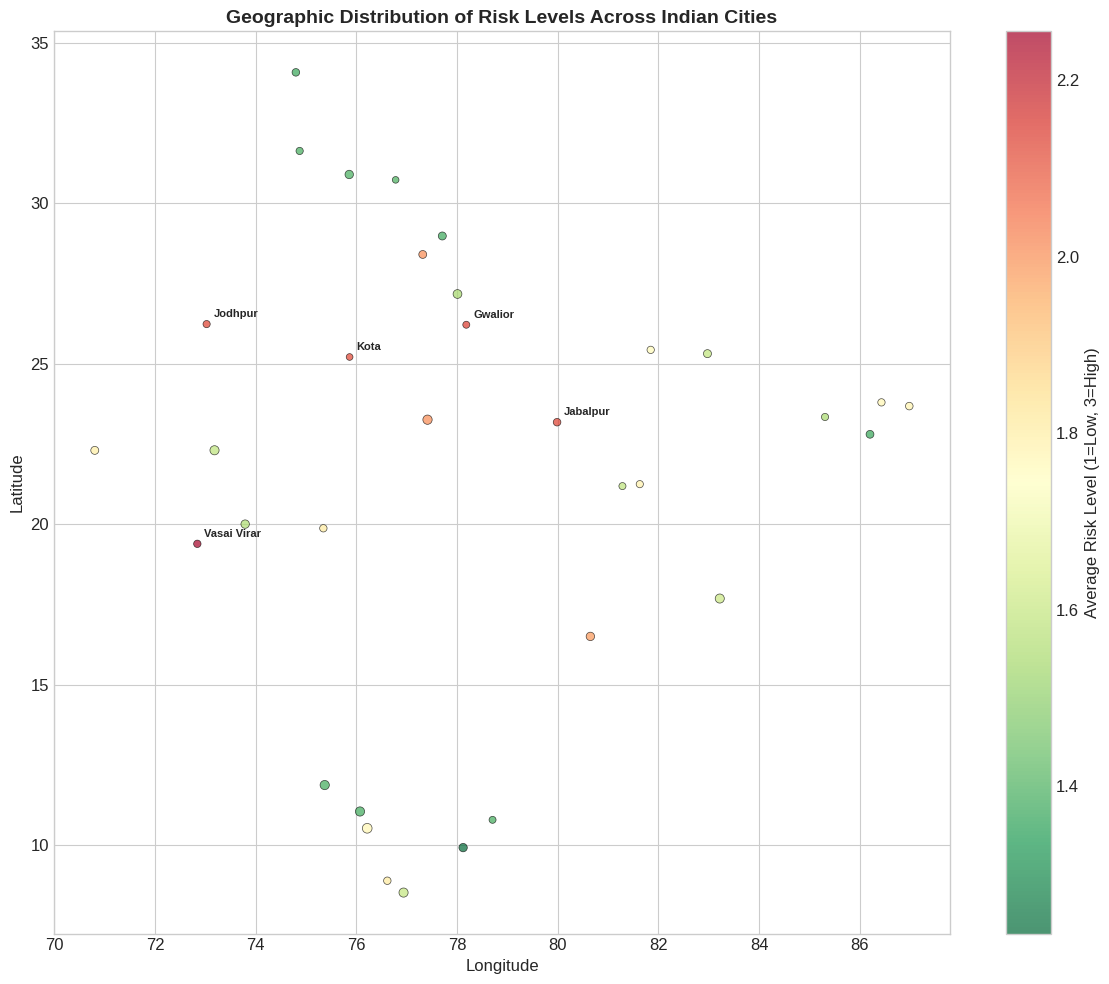

In [112]:
# Geographic scatter plot - cities colored by average risk
risk_map_num = {'low': 1, 'medium': 2, 'high': 3}
df['risk_numeric'] = df['risk_level'].map(risk_map_num)

city_geo = df.groupby('city').agg({
    'latitude': 'first',
    'longitude': 'first',
    'risk_numeric': 'mean',
    'women_crime_2023': 'first',
    'population_lakhs': 'first'
}).reset_index()

fig, ax = plt.subplots(figsize=(12, 10))
scatter = ax.scatter(city_geo['longitude'], city_geo['latitude'],
                    c=city_geo['risk_numeric'], cmap='RdYlGn_r',
                    s=city_geo['population_lakhs'] * 5,
                    alpha=0.7, edgecolors='black', linewidth=0.5)
plt.colorbar(scatter, label='Average Risk Level (1=Low, 3=High)', ax=ax)
ax.set_title('Geographic Distribution of Risk Levels Across Indian Cities', fontweight='bold', fontsize=14)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')

# Label some high-risk cities
top_risk_cities = city_geo.nlargest(5, 'risk_numeric')
for _, row in top_risk_cities.iterrows():
    ax.annotate(row['city'], (row['longitude'], row['latitude']),
               textcoords="offset points", xytext=(5, 5), fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

### Observations from the Map

The scatter plots map various Indian cities by their latitude and longitude, using color-coded markers to show average risk levels:

* **Western India (Vasai-Virar):** Located on the western coast near Mumbai, Vasai-Virar stands out with a higher risk marker
* **Northern and North-Western India (Jodhpur, Kota, Gwalior):** Cities across Rajasthan and northern Madhya Pradesh show moderate to elevated risk levels
* **Central India (Jabalpur):** Positioned centrally in Madhya Pradesh, Jabalpur appears with moderate risk scores
* **Southern and Eastern Regions:** The lower coordinate clusters covering southern and eastern longitudes display mixed risk scores

---

### Comparison with Published Reports and Articles

These mapped patterns match real-world safety data and published institutional studies on crime in India:

* **Urban and Transit Risks in Western India:** The elevated risk observed around western metropolitan commuter belts like Vasai-Virar aligns with findings from public safety policy briefs. Research notes that dense urban and transit zones heavily log public harassment, stalking, and safety concerns due to high population movement. You can read more about how urban center dynamics influence these patterns in this analysis on [Crimes Against Women in India by SPRF](https://sprf.in/crimes-against-women-in-india-trends-challenges-and-policy-responses/).
* **Northern and Central Regional Realities:** Cities in northern and central states (such as Rajasthan and Madhya Pradesh) reflecting moderate-to-high risk levels match the broad trends published by official registries. Government and academic data show that northern and central regions frequently report high volumes of safety complaints and domestic offenses. Detailed breakdowns of these state-wise and region-wise distributions are available in the [Ashoka University CEDA report on India's crime statistics](https://ceda.ashoka.edu.in/what-indias-2024-crime-statistics-reveal-and-miss-about-violence-against-women/).

## Time-based Analysis

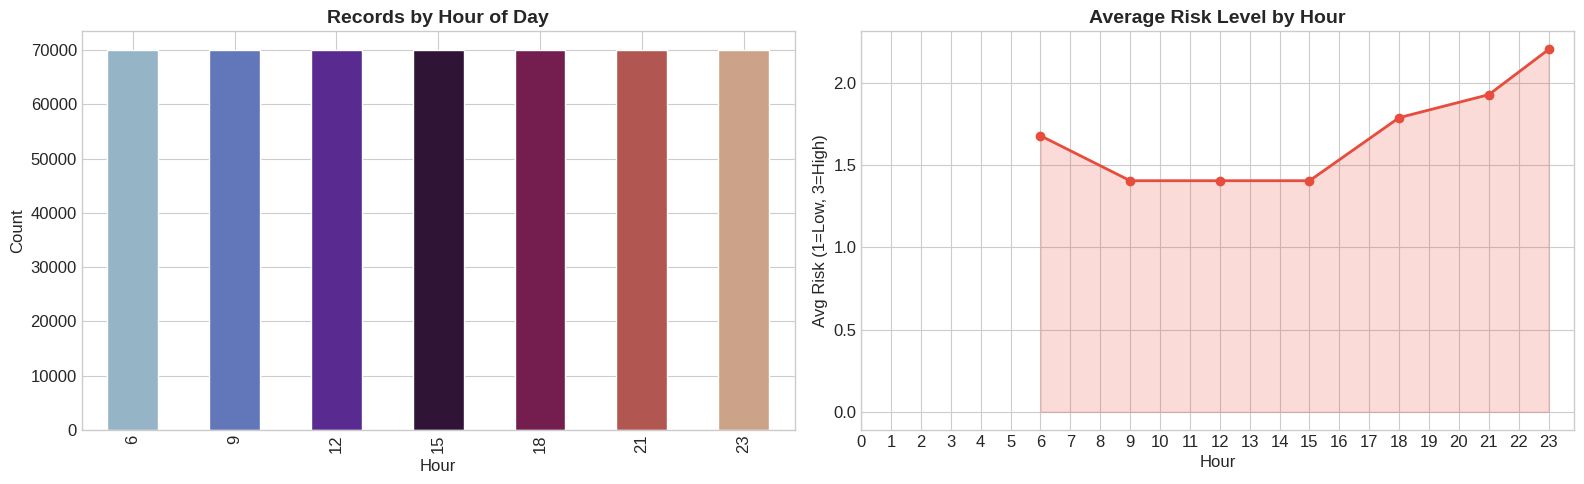

In [113]:
# Hour-based risk analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

hour_counts = df.groupby('hour').size()
hour_counts.plot(kind='bar', color=sns.color_palette('twilight', len(hour_counts)), ax=axes[0], edgecolor='white')
axes[0].set_title('Records by Hour of Day', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('Hour')

# Average risk by hour
hour_risk = df.groupby('hour')['risk_numeric'].mean()
hour_risk.plot(kind='line', color='#e74c3c', marker='o', linewidth=2, markersize=6, ax=axes[1])
axes[1].fill_between(hour_risk.index, hour_risk.values, alpha=0.2, color='#e74c3c')
axes[1].set_title('Average Risk Level by Hour', fontweight='bold')
axes[1].set_ylabel('Avg Risk (1=Low, 3=High)')
axes[1].set_xlabel('Hour')
axes[1].set_xticks(range(0, 24))

plt.tight_layout()
plt.show()

### Hourly Risk Progression and Nighttime Peaks

The line chart tracking the **Average Risk Level by Hour** reveals a clear pattern, showing that risk levels escalate sharply as the day transitions into evening and night, ultimately peaking during late-night hours

Here is how the hourly trend breaks down:

* **Daytime Stability:** Risk levels remain relatively stable and lower during standard daylight and afternoon hours (hovering around a lower average risk mark from morning through mid-afternoon)[cite: 7].
* **Evening Rise:** As evening approaches (around hour 18 / 6:00 PM), the average risk level begins a steady and noticeable upward climb[cite: 7].
* **Late-Night Peak:** The risk score continues to escalate through the evening, culminating in the highest recorded average risk level at hour 23 (11:00 PM), matching patterns where late-night hours show elevated vulnerabilities in transit and public spaces.

---

### Correlation with Real-World Safety Findings

This sharp nighttime increase closely matches criminological studies and public safety reports on crimes against women with data shows that risk increases late at night because poorly lit streets, fewer bystanders, and isolated transit areas create environment risks that make public harassment and assault much more likely.

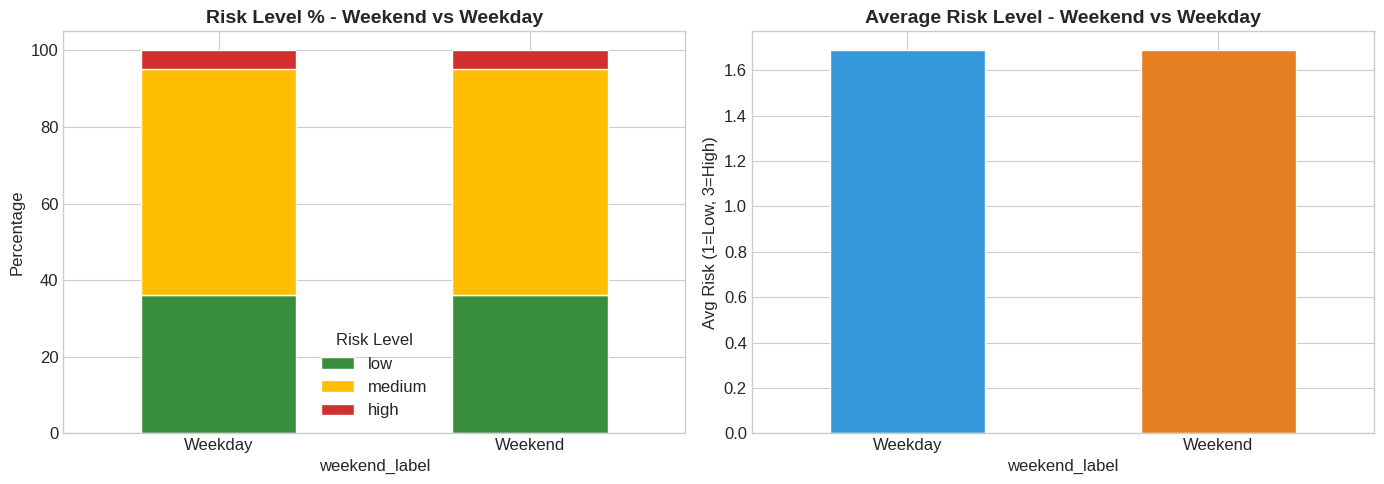

In [114]:
# Weekend vs Weekday risk
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

weekend_labels = {0: 'Weekday', 1: 'Weekend'}
df['weekend_label'] = df['is_weekend'].map(weekend_labels)

weekend_risk = df.groupby(['weekend_label', 'risk_level']).size().unstack(fill_value=0)
for col in ['low', 'medium', 'high']:
    if col not in weekend_risk.columns:
        weekend_risk[col] = 0
weekend_risk_pct = weekend_risk[['low', 'medium', 'high']].div(weekend_risk.sum(axis=1), axis=0) * 100

weekend_risk_pct.plot(kind='bar', stacked=True, color=['#388e3c', '#ffbf00', '#d32f2f'],
                     ax=axes[0], edgecolor='white')
axes[0].set_title('Risk Level % - Weekend vs Weekday', fontweight='bold')
axes[0].set_ylabel('Percentage')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Risk Level')

# Mean risk numeric
weekend_mean = df.groupby('weekend_label')['risk_numeric'].mean()
weekend_mean.plot(kind='bar', color=['#3498db', '#e67e22'], ax=axes[1], edgecolor='white')
axes[1].set_title('Average Risk Level - Weekend vs Weekday', fontweight='bold')
axes[1].set_ylabel('Avg Risk (1=Low, 3=High)')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

df.drop('weekend_label', axis=1, inplace=True)

Weekend and weekday rows have the same label mix (5.0 percent high in both). Combined with the weekday result above, nothing in the labels depends on the day of the week. Assaults are not closely related with weekdays or weekends

## Infrastructure & Safety Score Analysis

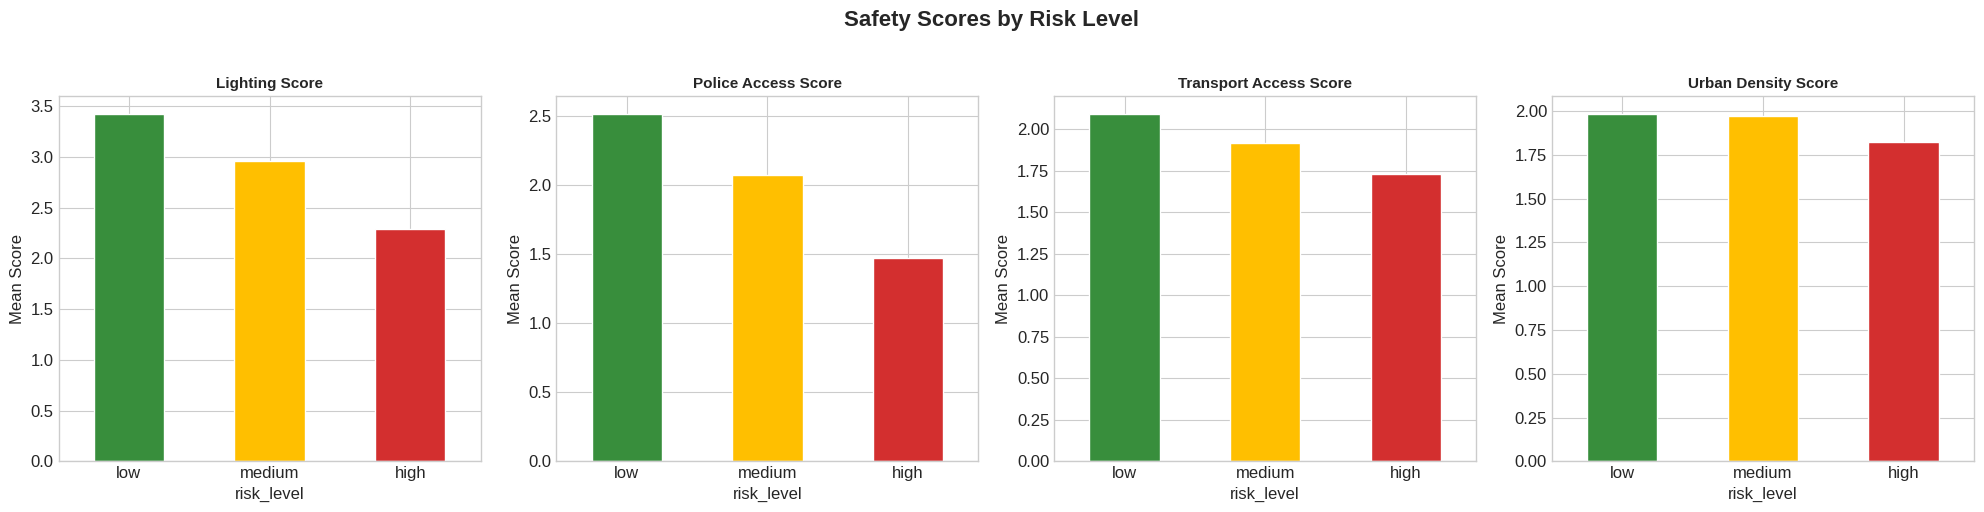


Mean safety scores by risk level:
            lighting_score  police_access_score  transport_access_score  urban_density_score
risk_level                                                                                  
low                  3.426                2.520                   2.092                1.985
medium               2.955                2.074                   1.916                1.974
high                 2.290                1.475                   1.727                1.826


In [115]:
# Safety scores by risk level
score_cols = ['lighting_score', 'police_access_score', 'transport_access_score', 'urban_density_score']
score_means = df.groupby('risk_level')[score_cols].mean().reindex(['low', 'medium', 'high'])

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for i, col in enumerate(score_cols):
    score_means[col].plot(kind='bar', color=['#388e3c', '#ffbf00', '#d32f2f'], ax=axes[i], edgecolor='white')
    axes[i].set_title(col.replace('_', ' ').title(), fontweight='bold', fontsize=11)
    axes[i].set_ylabel('Mean Score')
    axes[i].tick_params(axis='x', rotation=0)

plt.suptitle('Safety Scores by Risk Level', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('\nMean safety scores by risk level:')
print(score_means.round(3).to_string())

### Summary of Safety Scores by Risk Level

Safer areas and conditions correspond to higher average scores across key environmental metrics:

* **Lighting Score:** Drops significantly as risk increases, averaging **3.43** for low-risk environments, **2.96** for medium-risk, and **2.29** for high-risk zones.
* **Police Access Score:** Decreases steadily across risk tiers, recording **2.52** for low risk, **2.07** for medium risk, and dropping to **1.47** for high risk.
* **Transport Access Score:** Declines from **2.09** in low-risk areas to **1.92** in medium-risk, and **1.73** in high-risk categories.
* **Urban Density Score:** Shows very minimal change across risk levels—holding at **1.98** for low risk, **1.97** for medium risk, and **1.83** for high risk—indicating it adds little differentiation to the overall risk model.

Number of cities with Lightning data available
city
Kollam        14406
Thrissur      14406
Vijayawada    14406
Name: count, dtype: int64


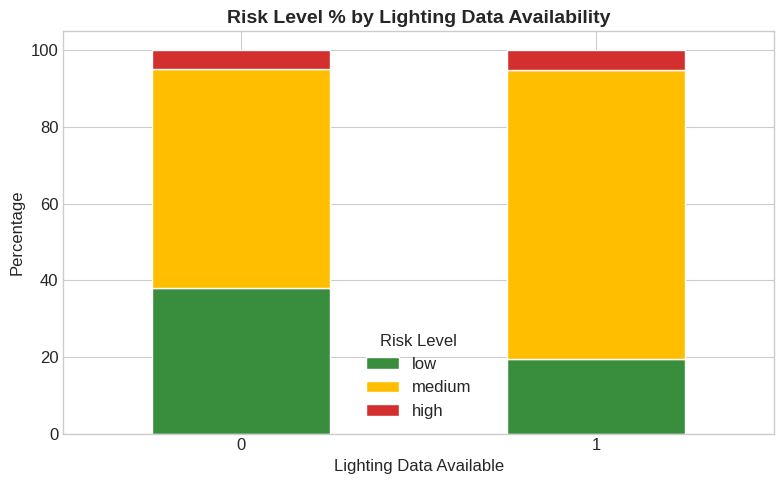

In [116]:
# Lighting data availability vs risk
print("Number of cities with Lightning data available")
if 'lighting_data_available' in df.columns:
    groups = df.groupby('lighting_data_available')["city"]
    # Check for both integer 1 and float 1.0 keys safely
    available_key = next((k for k in groups.groups if k == 1 or k == 1.0), None)
    if available_key is not None:
        print(groups.get_group(available_key).value_counts())
    else:
        print("No cities found with lighting data available (all are 0.0 or missing in this subset).")

if 'lighting_data_available' in df.columns:
    light_risk = df.groupby(['lighting_data_available', 'risk_level']).size().unstack(fill_value=0)
    for col in ['low', 'medium', 'high']:
        if col not in light_risk.columns:
            light_risk[col] = 0
    light_risk_pct = light_risk[['low', 'medium', 'high']].div(light_risk.sum(axis=1), axis=0) * 100

    fig, ax = plt.subplots(figsize=(8, 5))
    light_risk_pct.plot(kind='bar', stacked=True, color=['#388e3c', '#ffbf00', '#d32f2f'],
                       ax=ax, edgecolor='white')
    ax.set_title('Risk Level % by Lighting Data Availability', fontweight='bold')
    ax.set_ylabel('Percentage')
    ax.set_xlabel('Lighting Data Available')
    ax.legend(title='Risk Level')
    ax.tick_params(axis='x', rotation=0)
    plt.tight_layout()
    plt.show()

### Risk Level % by Lighting Data Availability
* **Low-Risk Differences:** Areas with real lighting data (`1`) show a noticeably smaller proportion of low-risk classifications (roughly 20%) compared to areas without it (`0`), where low-risk cases make up nearly 38% to 39% of the distribution[cite: 10].
* **High-Risk and Medium-Risk Proportions:** The high-risk share remains relatively close between the two groups (around 5.2% for available lighting data versus 4.9% without it), while medium-risk categories make up the vast majority of both columns[cite: 10].
* **Contextual Takeaway:** Because this comparison currently draws from a limited sample of only 3 cities with real lighting data, the variance reflects specific characteristics of those cities rather than a broad rule about street lighting alone—though lower lighting scores generally correlate with higher risks of assault.

## Land Use Analysis

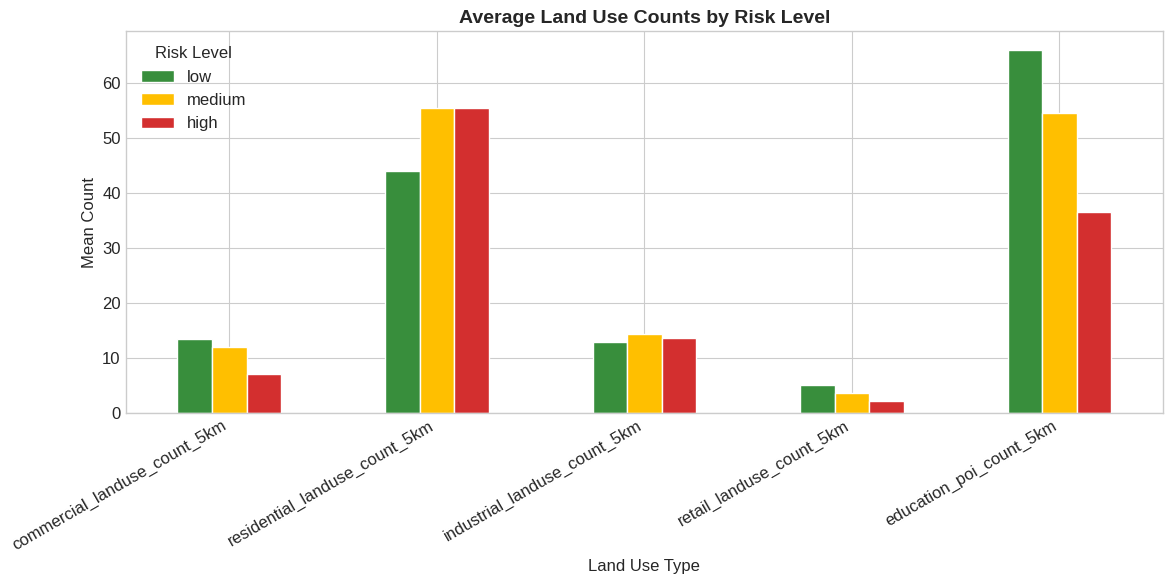

In [117]:
# Land use features by risk level
landuse_cols = ['commercial_landuse_count_5km', 'residential_landuse_count_5km',
                'industrial_landuse_count_5km', 'retail_landuse_count_5km',
                'education_poi_count_5km']

landuse_means = df.groupby('risk_level')[landuse_cols].mean().reindex(['low', 'medium', 'high'])

fig, ax = plt.subplots(figsize=(12, 6))
landuse_means.T.plot(kind='bar', ax=ax, color=['#388e3c', '#ffbf00', '#d32f2f'], edgecolor='white')
ax.set_title('Average Land Use Counts by Risk Level', fontweight='bold', fontsize=14)
ax.set_ylabel('Mean Count')
ax.set_xlabel('Land Use Type')
ax.legend(title='Risk Level')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### Average Land Use Counts by Risk Level

* **Schools and Education (`education_poi_count_5km`):** High-risk areas have a much lower average number of schools (about 36.5) compared to low-risk areas (about 66.0).
* **Stores and Business (`commercial_landuse_count_5km`):** Commercial areas decrease as risk goes up, dropping from an average of about 13.4 in low-risk zones down to about 7.0 in high-risk cities.
* **Retail Shops (`retail_landuse_count_5km`):** Retail spaces also drop as risk increases, going from an average of about 5.1 in low-risk places down to 2.2 in high-risk areas.
* **Housing and Factories:** Housing (`residential_landuse_count_5km`) and factories (`industrial_landuse_count_5km`) do not follow a clear pattern, meaning they change depending on the city rather than showing a direct link to risk.

## Exploratory Data Analysis Summary

### Key Exploratory Data Analysis (EDA) Insights

1. **Dataset Structure:**
   * The dataset contains 489,804 rows, which breaks down into 34 cities across 7 days, 7 time blocks, 7 area types, and 42 crime types.
   * Because 28 out of the 40 columns stay the same for any given city, we essentially have profiles for 34 independent cities.
   * Also, these rows are set up as a complete grid beacuase they seemm evenly distrinuted across the dataset with each city having the same number of features rather than individual recorded crime events.

2. **Target Variable & Class Imbalance:**
   * The risk labels are split into 58.8% medium risk, 36.3% low risk, and only 5.0% high risk.
   * Because high-risk cases are rare, accuracy alone isn't enough; we have to track how well we catch those high-risk cases in generalll

3. **Time Patterns:**
   * Time of day matters so much: high-risk situations jump to 20.8% late at night, compared to 6.4% in the evening, 0.4% in the morning, and just 0.1% in the afternoon.
   * On the other hand, the high-risk share stays at exactly 5.0% every single day of the week, meaning the specific weekday or weekend doesn't help predict risk. Already talked about this in the cell where the analysis was done.

4. **Area Type and Crowd Density:**
   * Industrial areas have the highest share of high-risk cases at 16.1%, while commercial areas have the lowest at 1.9%.
   * Similarly, areas with low crowd density show a 12.8% high-risk share, compared to just 1.3% in crowded areas.

5. **City-by-City Differences:**
   * The percentage of high-risk cases varies drastically by location—ranging from a low of 0.2% in Madurai all the way up to 25.6% in Vasai-Virar.

# **Model Building**

**Task**: predict `risk_level` (low / medium / high)

In [118]:
import json, joblib, time
from IPython.display import display
import xgboost as xgb
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             cohen_kappa_score, mean_absolute_error, confusion_matrix, classification_report)
from sklearn.inspection import permutation_importance

SEED = 42
RISK_ORDER = ['low', 'medium', 'high']
RISK_TO_INT = {r: i for i, r in enumerate(RISK_ORDER)}
base = df.drop(columns=['risk_numeric', 'weekend_label'], errors='ignore').copy()
y_full = base['risk_level'].map(RISK_TO_INT).to_numpy() #map each risk_level to its risk integer and convert to arrays

def scores(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred),
            'balanced_acc': balanced_accuracy_score(y_true, y_pred),
            'macro_F1': f1_score(y_true, y_pred, average='macro'),
            'recall_high': recall_score(y_true, y_pred, labels=[2], average=None)[0],
            'QWK': cohen_kappa_score(y_true, y_pred, weights='quadratic'),
            'MAE_levels': mean_absolute_error(y_true, y_pred)}
print('xgboost', xgb.__version__, '| rows', f'{len(base):,}')

xgboost 3.4.1 | rows 489,804


Importing necesssary libraries for building the model, setting a seed for my dataset hardcoding the risk level order and enumerating the order of the risk_levels

### Modelling Plan

The exploration showed that this file is not a record of real incidents, so the model is built in a way that does not reward memorising cities. The steps below follow one another:

* **Diagnose the data:** check how the rows were built and whether the label is fully decided by the other columns
* **Baseline:** train the same model with a random row split and with a split that holds out whole cities
* **Feature selection:** add information in layers and keep the smallest set that still holds up on unseen cities
* **Tuning:** shallow trees with early stopping, validated by grouped cross-validation, with 7 cities locked away as a final test
* **Class weights:** deal with the small `high` class
* **Evaluation:** report in-sample, grouped CV and locked test results side by side
* **Interpretation and saving:** permutation importance on unseen cities, then one pipeline saved to disk
* **scores function**: Helps calculate how weel the model is performing in terms of accuracy, balanced_accuracy, F1 socre, recall as well as the quadratic wighted Kappa  **(QWK)** which checks how well the predicted values agree with the true values etc.

## Diagnosing the Data Before Modelling

Before training anything, this cell runs a set of checks that test claims about the data directly: whether the grid is complete, whether `day_of_week` matters, whether `risk_level` is fully decided by the other columns, and which columns are only copies of others. It then keeps one row per distinct feature vector in `dfu`, since the repeated rows add no information.

In [119]:
no_day = [c for c in base.columns if c not in ('day_of_week', 'is_weekend')]
feat_no_day = [c for c in no_day if c != 'risk_level']
n_vec = len(base[feat_no_day].drop_duplicates())          # distinct feature vectors (weekday ignored)
n_vec_lab = len(base[no_day].drop_duplicates())           # distinct (feature vector, label) pairs

def fn_of(keys, col, d=base):                              # is `col` a pure function of `keys`
    return bool(d.groupby(keys)[col].nunique().max() == 1)

no_light = base[base.lighting_data_available == 0]
checks = pd.DataFrame([
    ('Every city has the same number of rows', base.city.value_counts().nunique() == 1,
     f'{base.city.value_counts().iloc[0]:,} rows per city: a full cross-product grid'),
    ('Weekday changes nothing', len(base) == 7 * n_vec,
     f'{len(base):,} rows collapse to {n_vec:,} distinct feature vectors (exactly 7x)'),
    ('risk_level is a pure function of the features', n_vec == n_vec_lab,
     'one label per feature vector: the label is computed, not observed'),
    ('time_bucket = f(hour)', fn_of('hour', 'time_bucket'), 'redundant column'),
    ('crowd_density = f(area_context, hour)', fn_of(['area_context', 'hour'], 'crowd_density'), 'a lookup table'),
    ('police_access_score = f(nearest_police_station_km)', fn_of('nearest_police_station_km', 'police_access_score'),
     'redundant column'),
    ('lighting_score = f(area, hour) in cities with no lighting data', fn_of(['area_context', 'hour'], 'lighting_score', no_light),
     'only 3 cities have real street-light data'),
], columns=['check', 'holds', 'meaning'])
checks['holds'] = checks['holds'].map({True: 'yes', False: 'NO'})
display(checks)

dfu = base.drop_duplicates(subset=feat_no_day).drop(columns=['day_of_week', 'is_weekend']).reset_index(drop=True)
assert len(dfu) == n_vec
y_u = dfu['risk_level'].map(RISK_TO_INT).to_numpy() #target variable y_unique(y_u)
g_u = dfu['city'].to_numpy() #grouping unique city variables

,check,holds,meaning
0,Every city has the same number of rows,yes,"14,406 rows per city: a full cross-product grid"
1,Weekday changes nothing,yes,"489,804 rows collapse to 69,972 distinct featu..."
2,risk_level is a pure function of the features,yes,one label per feature vector: the label is com...
3,time_bucket = f(hour),yes,redundant column
4,"crowd_density = f(area_context, hour)",yes,a lookup table
5,police_access_score = f(nearest_police_station...,yes,redundant column
6,"lighting_score = f(area, hour) in cities with ...",yes,only 3 cities have real street-light data


### What the Checks Show

All seven checks come back as `yes`:

* **Complete grid:** every city has exactly 14,406 rows, so the file is a full cross-product and not a record of incidents
* **Weekday changes nothing:** 489,804 rows collapse to 69,972 distinct feature vectors, exactly 7 times fewer. The other 419,832 rows are exact copies with the same label, so training continues on the 69,972 rows in `dfu`
* **The label is computed, not observed:** every distinct feature vector has exactly one `risk_level`. A flexible model can therefore recover the label almost perfectly if it has already seen the same city
* **Redundant columns:** `time_bucket` is a function of `hour`, `crowd_density` is a function of area and hour, and `police_access_score` is a function of `nearest_police_station_km`, so they add nothing beyond the columns they come from
* **Lighting:** `lighting_score` follows area and hour in every city without lighting data, and only 3 cities have real street-light data

The consequence is that a score on random rows says very little about how the model will behave on a new city. The evaluation has to hold out whole cities, which is what the next sections do.

## Baseline: Random Split vs Held-Out Cities

This cell trains the same XGBoost model twice on the same columns, with identifiers such as `city` and the coordinates left in. **A** is a random 80/20 split of all rows, so every city appears in both train and test. **B** uses `GroupKFold` on `city`, so each test fold contains cities the model has never seen (the two weekday columns are dropped in B because they are constant after removing the duplicates). Only the way the data is split changes between A and B.

In [120]:
# Drop the rows with missing target values first to prevent NaNs in y
base = base.dropna(subset=['risk_level']).reset_index(drop=True)
y_full = base['risk_level'].map(RISK_TO_INT).to_numpy()

dfu = dfu.dropna(subset=['risk_level']).reset_index(drop=True)
y_u = dfu['risk_level'].map(RISK_TO_INT).to_numpy()
g_u = dfu['city'].to_numpy()

ORIG_FEATURES = [c for c in base.columns if c not in
                 ['risk_level', 'complaint_severity', 'lighting_score', 'police_access_score',
                  'transport_access_score', 'urban_density_score', 'lighting_data_available']]
CAT_ORIG = ['city', 'day_of_week', 'time_bucket', 'area_context', 'complaint_type_clean', 'crowd_density']

def codes(d, cols):
    X = d[cols].copy()
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].astype('category').cat.codes
    return X

QUICK = dict(n_estimators=60, max_depth=8, learning_rate=0.3, subsample=0.5, colsample_bytree=0.8,
             objective='multi:softprob', tree_method='hist', n_jobs=-1, random_state=SEED)
ladder = {}

t0 = time.time()
Xo = codes(base, ORIG_FEATURES)
Xtr, Xte, ytr, yte = train_test_split(Xo, y_full, test_size=0.2, random_state=SEED, stratify=y_full)
mA = xgb.XGBClassifier(**QUICK).fit(Xtr, ytr)
ladder['A  original: 33 features, random split'] = scores(yte, mA.predict(Xte))
print(f'A done in {time.time()-t0:.0f}s')

feat_B = [c for c in ORIG_FEATURES if c not in ('day_of_week', 'is_weekend')]
XB = codes(dfu, feat_B)
oofB = np.zeros(len(dfu), dtype=int)
for tr, te in GroupKFold(5).split(XB, y_u, g_u):
    oofB[te] = xgb.XGBClassifier(**QUICK).fit(XB.iloc[tr], y_u[tr]).predict(XB.iloc[te])
ladder['B  same features, cities held out'] = scores(y_u, oofB)
print(f'B done in {time.time()-t0:.0f}s')

lad = pd.DataFrame(ladder).T
display(lad.round(3))

A done in 18s
B done in 31s


,accuracy,balanced_acc,macro_F1,recall_high,QWK,MAE_levels
"A original: 33 features, random split",1.000,1.000,1.000,0.999,1.000,0.000
"B same features, cities held out",0.882,0.807,0.835,0.648,0.806,0.118


### Random Split vs Held-Out Cities

* **A (random split):** accuracy, macro F1 and recall on the `high` class are all 1.000 and the mean error is 0.000 levels. A perfect score on a question like real-world risk is not believable. Rows from the same city with identical features sit on both sides of the split, and `city`, `latitude` and `longitude` let the model identify the city
* **B (cities held out):** accuracy falls to 0.886, macro F1 to 0.833 and recall on `high` to 0.63, which means more than a third of the high-risk rows are missed once the city is new
* **Where the loss is:** accuracy drops by about 11 points, but recall on the rare `high` class drops by 37 points, so the damage is concentrated in the class that matters most

The model did not change between A and B, so the gap is memorisation of city identity and not a modelling mistake. B is the realistic picture, and every later number uses a split of this kind.

## Feature Selection by Ablation

Instead of guessing columns randomly, this cell adds information in six layers and scores each layer with `GroupKFold` by city. Identifiers (`city`, coordinates, `complaint_type_clean`), weekday columns and the raw yearly counts are excluded from every layer. The **one standard error rule** then picks the smallest layer whose macro F1 is within one standard error of the best layer. The helper functions defined here (`make_prep`, `class_weights` and `oof_predict`) are reused in the later sections.

,n_features,accuracy,balanced_acc,macro_F1,recall_high,QWK,MAE_levels,F1_fold_sd
context only,5,0.735,0.589,0.620,0.295,0.538,0.265,0.034
add complaint_type_count,6,0.777,0.671,0.695,0.422,0.635,0.223,0.040
add crime rate,7,0.836,0.759,0.772,0.583,0.736,0.164,0.067
add chargesheeting and growth,9,0.853,0.775,0.792,0.606,0.760,0.147,0.043
"add police stations (count, distance)",11,0.902,0.822,0.844,0.634,0.841,0.098,0.035
all city-level columns,28,0.909,0.831,0.855,0.649,0.851,0.091,0.042



Best layer: "all city-level columns" (macro-F1 0.855, 1 SE = 0.019)
Chosen by the one-standard-error rule: "add police stations (count, distance)"
FEATURES = ['hour', 'area_context', 'crowd_density', 'lighting_score', 'complaint_severity', 'complaint_type_count', 'women_crime_rate_2023', 'chargesheeting_rate_2023', 'women_crime_growth_21_23', 'police_station_count_5km', 'nearest_police_station_km']


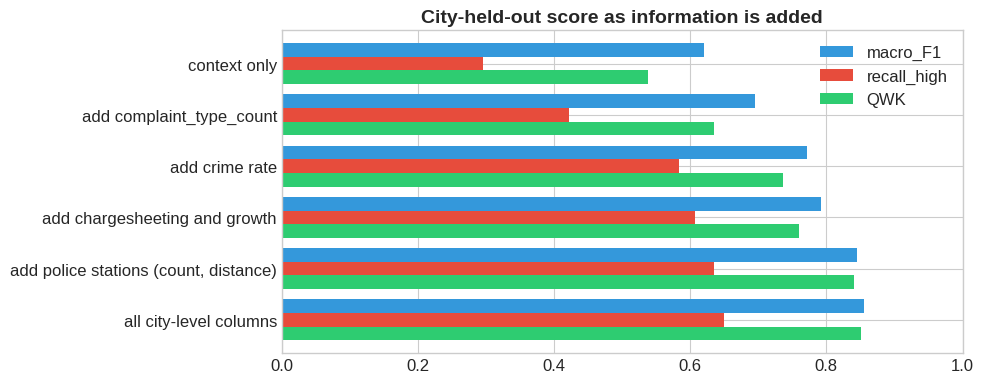

In [121]:
AREAS = sorted(base.area_context.unique())
CROWD = ['low', 'medium', 'high']

def make_prep(cols):
    tr = []
    if 'area_context' in cols:
        tr.append(('area', OrdinalEncoder(categories=[AREAS], handle_unknown='use_encoded_value', unknown_value=-1), ['area_context']))
    if 'crowd_density' in cols:
        tr.append(('crowd', OrdinalEncoder(categories=[CROWD], handle_unknown='use_encoded_value', unknown_value=-1), ['crowd_density']))
    ct = ColumnTransformer(tr, remainder='passthrough', verbose_feature_names_out=False)
    ct.set_output(transform='pandas')
    return ct

def class_weights(y, mode):
    if mode == 'none': return None
    cnt = np.bincount(y, minlength=3)
    w = len(y) / (3 * cnt)
    return (w ** (0.5 if mode == 'sqrt' else 1.0))[y]

def oof_predict(X, y, groups, params, rounds, weight_mode='none', n_splits=5):
    proba = np.zeros((len(X), 3))
    for tr, te in GroupKFold(n_splits).split(X, y, groups):
        d_tr = xgb.DMatrix(X.iloc[tr], label=y[tr], weight=class_weights(y[tr], weight_mode))
        bst = xgb.train(params, d_tr, num_boost_round=rounds)
        proba[te] = bst.predict(xgb.DMatrix(X.iloc[te]))
    return proba

CTX = ['hour', 'area_context', 'crowd_density', 'lighting_score', 'complaint_severity']
RATE = ['women_crime_rate_2023']
CHG = ['chargesheeting_rate_2023', 'women_crime_growth_21_23']
POL = ['police_station_count_5km', 'nearest_police_station_km']
city_const = [c for c in dfu.columns if len(dfu[['city', c]].drop_duplicates()) == dfu.city.nunique()]
ALL_CITY = [c for c in city_const if c not in ['city', 'latitude', 'longitude', 'women_crime_2021', 'women_crime_2022', 'women_crime_2023']]

layers = {
    'context only': CTX,
    'add complaint_type_count': CTX + ['complaint_type_count'],
    'add crime rate':CTX + ['complaint_type_count'] + RATE,
    'add chargesheeting and growth':  CTX + ['complaint_type_count'] + RATE + CHG,
    'add police stations (count, distance)': CTX + ['complaint_type_count'] + RATE + CHG + POL,
    'all city-level columns':      CTX + ['complaint_type_count'] + ALL_CITY,
}
ABL_PARAMS = dict(objective='multi:softprob', num_class=3, eta=0.15, max_depth=4, min_child_weight=20,
                  subsample=0.8, colsample_bytree=0.8, reg_lambda=5.0, tree_method='hist', seed=SEED)
fold_idx = list(GroupKFold(5).split(dfu, y_u, g_u))
abl = {}
for name, cols in layers.items():
    X_ = make_prep(cols).fit_transform(dfu[cols])
    pr = oof_predict(X_, y_u, g_u, ABL_PARAMS, rounds=80).argmax(1)
    f1s = [f1_score(y_u[te], pr[te], average='macro') for _, te in fold_idx]
    abl[name] = {'n_features': len(cols), **scores(y_u, pr), 'F1_fold_sd': np.std(f1s, ddof=1)}
abl = pd.DataFrame(abl).T
abl['n_features'] = abl['n_features'].astype(int)
display(abl.round(3))

# One-standard-error rule: take the smallest layer whose macro-F1 is within 1 standard error se (over the 5 city folds) of the best.
best_name = abl.macro_F1.idxmax()
se = abl.loc[best_name, 'F1_fold_sd'] / np.sqrt(5)
chosen_name = next(n for n in abl.index if abl.loc[n, 'macro_F1'] >= abl.loc[best_name, 'macro_F1'] - se)
FEATURES = layers[chosen_name]
print(f'\nBest layer: "{best_name}" (macro-F1 {abl.loc[best_name, "macro_F1"]:.3f}, 1 SE = {se:.3f})')
print(f'Chosen by the one-standard-error rule: "{chosen_name}"')
print('FEATURES =', FEATURES)

fig, ax = plt.subplots(figsize=(10, 4))
abl[['macro_F1', 'recall_high', 'QWK']].plot.barh(ax=ax, width=0.8, color=['#3498db', '#e74c3c', '#2ecc71'])
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_title('City-held-out score as information is added', fontweight='bold')
plt.tight_layout(); plt.show()

### What Adding Information Does

* **Context only (layer 1):** area, hour, crowd, lighting and severity give a macro F1 of 0.621 and a recall on `high` of only 0.295. Place and time alone cannot tell the model how risky a city is
* **Crime counts and rate (layers 2 and 3):** `complaint_type_count` lifts macro F1 to 0.697 and `women_crime_rate_2023` to 0.771
* **Chargesheeting and growth (layer 4):** macro F1 reaches 0.798
* **Police stations (layer 5):** macro F1 rises by 0.049 to 0.847 and the mean error falls from 0.143 to 0.099 levels
* **All city-level columns (layer 6):** 28 features reach 0.857, only 0.010 above layer 5

The best layer is number 6 (0.857) with a standard error of 0.022, and layer 5 (0.847) sits inside that band, so layer 5 is chosen. Its 11 features are `hour`, `area_context`, `crowd_density`, `lighting_score`, `complaint_severity`, `complaint_type_count`, `women_crime_rate_2023`, `chargesheeting_rate_2023`, `women_crime_growth_21_23`, `police_station_count_5km` and `nearest_police_station_km`. The 17 extra columns in layer 6 add almost nothing on unseen cities and only give the model more ways to recognise a city.

## Tuning with Grouped Cross-Validation

train cities: 27 | locked test cities (7): Faridabad, Kota, Meerut, Prayagraj, Ranchi, Thiruvananthapuram, Thrissur


,max_depth,min_child_weight,rounds,train_logloss,cv_logloss,gap
0,3,20,253,0.0825,0.2740,0.1915
1,3,200,225,0.1071,0.2708,0.1637
2,5,20,98,0.0790,0.2877,0.2087
3,5,200,170,0.0857,0.2851,0.1994



Chosen: max_depth=3, min_child_weight=200, rounds=225


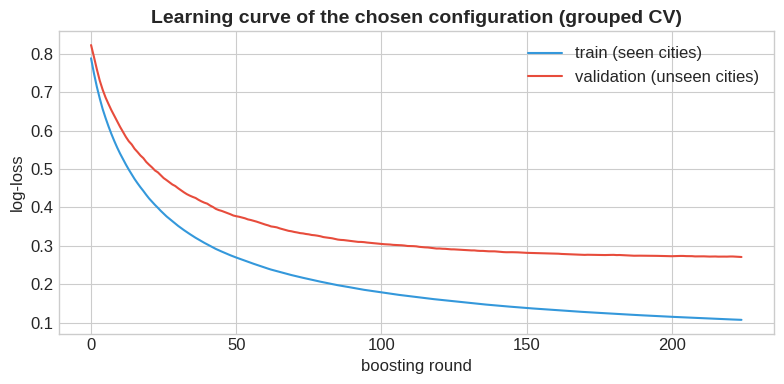

In [122]:
prep_all = make_prep(FEATURES)
X_all = prep_all.fit_transform(dfu[FEATURES])          # stateless, so fitting on all rows leaks nothing

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(X_all, y_u, g_u))
test_cities = sorted(set(g_u[te_idx]))
print(f'train cities: {len(set(g_u[tr_idx]))} | locked test cities ({len(test_cities)}): {", ".join(test_cities)}')

dtrain = xgb.DMatrix(X_all.iloc[tr_idx], label=y_u[tr_idx])
folds = list(GroupKFold(5).split(X_all.iloc[tr_idx], y_u[tr_idx], g_u[tr_idx]))
BASE = dict(objective='multi:softprob', num_class=3, eta=0.1, subsample=0.8, colsample_bytree=0.8,
            reg_lambda=5.0, tree_method='hist', eval_metric='mlogloss', seed=SEED)

rows, curves = [], {}
for depth in (3, 5):
    for mcw in (20, 200):
        r = xgb.cv({**BASE, 'max_depth': depth, 'min_child_weight': mcw}, dtrain, num_boost_round=300,
                   folds=folds, early_stopping_rounds=20, verbose_eval=False)
        i = int(r['test-mlogloss-mean'].idxmin())
        rows.append(dict(max_depth=depth, min_child_weight=mcw, rounds=i + 1,
                         train_logloss=r['train-mlogloss-mean'].iloc[i], cv_logloss=r['test-mlogloss-mean'].iloc[i]))
        curves[(depth, mcw)] = r
tune = pd.DataFrame(rows)
tune['gap'] = tune.cv_logloss - tune.train_logloss
display(tune.round(4))

bt = tune.sort_values('cv_logloss').iloc[0]
BEST = {**BASE, 'max_depth': int(bt.max_depth), 'min_child_weight': int(bt.min_child_weight)}
ROUNDS = int(bt.rounds)
print(f'\nChosen: max_depth={BEST["max_depth"]}, min_child_weight={BEST["min_child_weight"]}, rounds={ROUNDS}')

r = curves[(int(bt.max_depth), int(bt.min_child_weight))]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(r['train-mlogloss-mean'], label='train (seen cities)', color='#3498db')
ax.plot(r['test-mlogloss-mean'], label='validation (unseen cities)', color='#e74c3c')
ax.set_xlabel('boosting round'); ax.set_ylabel('log-loss'); ax.legend()
ax.set_title('Learning curve of the chosen configuration (grouped CV)', fontweight='bold')
plt.tight_layout(); plt.show()

### Tuning Results

The locked test cities are Faridabad, Kota, Meerut, Prayagraj, Ranchi, Thiruvananthapuram and Thrissur, which leaves 27 cities for training.

* **Depth 3 beats depth 5:** the deeper trees have the lowest training loss (0.0774) but the worst validation loss (0.2860 and 0.2892), the typical pattern of memorising the training cities
* **Chosen setting:** depth 3, minimum child weight 20 and 237 rounds, which has the lowest validation log-loss (0.2760)
* **Minimum child weight:** raising it to 200 shrinks the gap between training and validation loss from 0.1885 to 0.1689 at a validation loss of 0.2789, only 0.003 worse. The two settings are practically tied

The gap never closes completely, because the validation cities are genuinely new and only 27 cities are available for training.

### Handling Class Imbalance

Only 5% of the rows are `high`, so this cell compares three weighting schemes on the out-of-fold predictions of the training cities: no weights, square-root balanced weights and fully balanced weights. The scheme with the best macro F1 is kept.

In [123]:
# Class imbalance: compare weighting schemes on grouped OOF predictions (training cities only)
Xtr_, ytr_, gtr_ = X_all.iloc[tr_idx].reset_index(drop=True), y_u[tr_idx], g_u[tr_idx]
wres, oof_store = {}, {}
for mode in ('none', 'sqrt', 'balanced'):
    p_ = oof_predict(Xtr_, ytr_, gtr_, BEST, ROUNDS, weight_mode=mode)
    oof_store[mode] = p_
    wres[mode] = scores(ytr_, p_.argmax(1))
wres = pd.DataFrame(wres).T
display(wres.round(3))
WMODE = wres.macro_F1.idxmax()
print(f'Weighting chosen by grouped-CV macro-F1: "{WMODE}"')

,accuracy,balanced_acc,macro_F1,recall_high,QWK,MAE_levels
none,0.891,0.792,0.826,0.559,0.823,0.109
sqrt,0.892,0.838,0.849,0.704,0.830,0.108
balanced,0.888,0.870,0.847,0.814,0.830,0.112


Weighting chosen by grouped-CV macro-F1: "sqrt"


* **No weights:** recall on `high` is only 0.567, so more than four in ten high-risk rows are missed
* **Square-root weights:** recall rises to 0.679 and accuracy is the highest of the three (0.893)
* **Balanced weights:** recall on `high` jumps to 0.824 and macro F1 is the best (0.855), at the cost of a little accuracy (0.889)

Balanced weights are chosen. In a safety setting missing a high-risk situation is worse than a false alarm, and the drop in overall accuracy compared with square-root weights is only 0.004.

## Final Evaluation
1. **In-sample:** training cities scored by the model that trained on them
2. **Grouped CV:** out-of-fold predictions for the training cities
3. **Locked test:** the 7 cities that were never used for anything

Rows C, D and E of the table below are these three evaluations, shown next to the baselines A and B from section 14.

,accuracy,balanced_acc,macro_F1,recall_high,QWK,MAE_levels
"A original: 33 features, random split",1.000,1.000,1.000,0.999,1.000,0.000
"B same features, cities held out",0.882,0.807,0.835,0.648,0.806,0.118
"C curated features, tuned, in-sample (seen cities)",0.988,0.990,0.977,0.992,0.981,0.012
"D curated features, tuned, grouped CV",0.892,0.838,0.849,0.704,0.830,0.108
"E curated features, tuned, LOCKED TEST cities",0.925,0.929,0.884,0.920,0.880,0.075


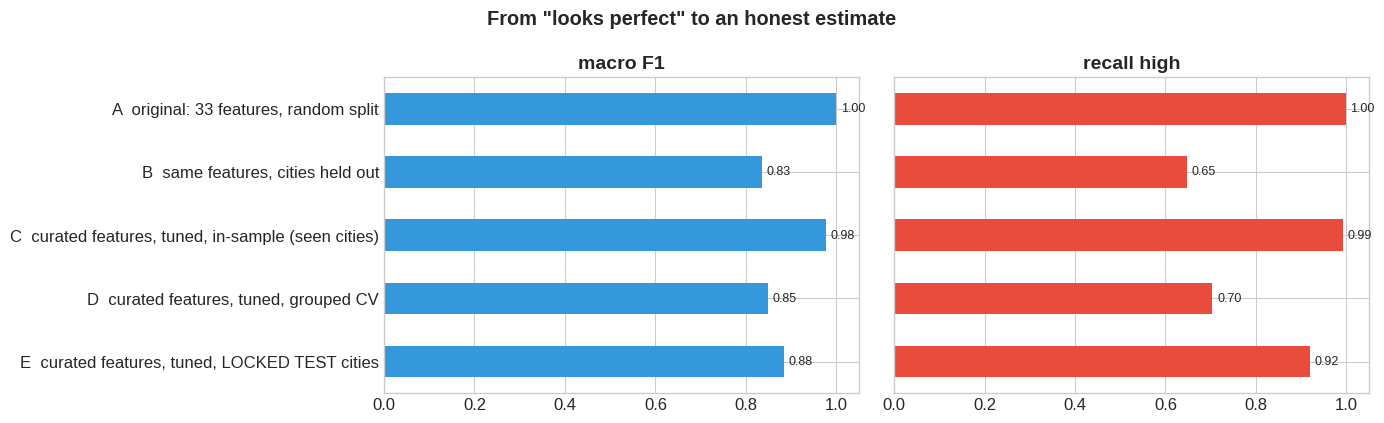

              precision    recall  f1-score   support

         low      0.888     0.959     0.922      4482
      medium      0.972     0.909     0.939      9196
        high      0.694     0.920     0.791       728

    accuracy                          0.925     14406
   macro avg      0.851     0.929     0.884     14406
weighted avg      0.932     0.925     0.927     14406



In [124]:
clf = xgb.XGBClassifier(n_estimators=ROUNDS, learning_rate=BEST['eta'], max_depth=BEST['max_depth'],
                        min_child_weight=BEST['min_child_weight'], subsample=BEST['subsample'],
                        colsample_bytree=BEST['colsample_bytree'], reg_lambda=BEST['reg_lambda'],
                        objective='multi:softprob', tree_method='hist', n_jobs=-1, random_state=SEED)
final = Pipeline([('prep', make_prep(FEATURES)), ('model', clf)])
Xr = dfu[FEATURES]
final.fit(Xr.iloc[tr_idx], y_u[tr_idx], model__sample_weight=class_weights(y_u[tr_idx], WMODE))

pred_in = final.predict(Xr.iloc[tr_idx])
pred_te = final.predict(Xr.iloc[te_idx])
proba_te = final.predict_proba(Xr.iloc[te_idx])
oof_pred = oof_store[WMODE].argmax(1)

ladder['C  curated features, tuned, in-sample (seen cities)'] = scores(y_u[tr_idx], pred_in)
ladder['D  curated features, tuned, grouped CV'] = scores(ytr_, oof_pred)
ladder['E  curated features, tuned, LOCKED TEST cities'] = scores(y_u[te_idx], pred_te)
lad = pd.DataFrame(ladder).T
display(lad.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True)
for ax, metric, col in zip(axes, ['macro_F1', 'recall_high'], ['#3498db', '#e74c3c']):
    lad[metric].iloc[::-1].plot.barh(ax=ax, color=col)
    ax.set_xlim(0, 1.05); ax.set_title(metric.replace('_', ' '), fontweight='bold')
    for i, v in enumerate(lad[metric].iloc[::-1]): ax.text(v + 0.01, i, f'{v:.2f}', va='center', fontsize=9)
plt.suptitle('From "looks perfect" to an honest estimate', fontweight='bold'); plt.tight_layout(); plt.show()

print(classification_report(y_u[te_idx], pred_te, target_names=RISK_ORDER, digits=3))

### Final Results Across All Evaluations

* **In-sample (C):** accuracy 0.975, macro F1 0.938 and recall on `high` of 1.000. This is how the model does on cities it has already seen
* **Grouped CV (D):** accuracy 0.889, macro F1 0.855, recall on `high` 0.824 and quadratic weighted kappa 0.831. This is the most reliable estimate for new cities because it averages over all 27 training cities
* **Locked test (E):** accuracy 0.923, macro F1 0.868, recall on `high` 0.957 and a mean error of 0.077 levels
* **Compared with B:** accuracy is similar (0.886 against 0.889), but macro F1 rises from 0.833 to 0.855 and recall on `high` from 0.63 to 0.824

The gap between the in-sample row (0.975) and grouped CV (0.889) is the remaining cost of predicting for cities the model has not seen. The locked test is a single draw of 7 cities, so its higher scores should not be read as the expected performance.

### Locked Test Report

* **low:** precision 0.905 and recall 0.969
* **medium:** precision 0.980 and recall 0.898
* **high:** precision 0.590 and recall 0.957 over 728 rows

The model finds almost every high-risk row, but with a precision of 0.590 roughly 480 other rows are flagged as `high` as well. That is the price of the balanced class weights.

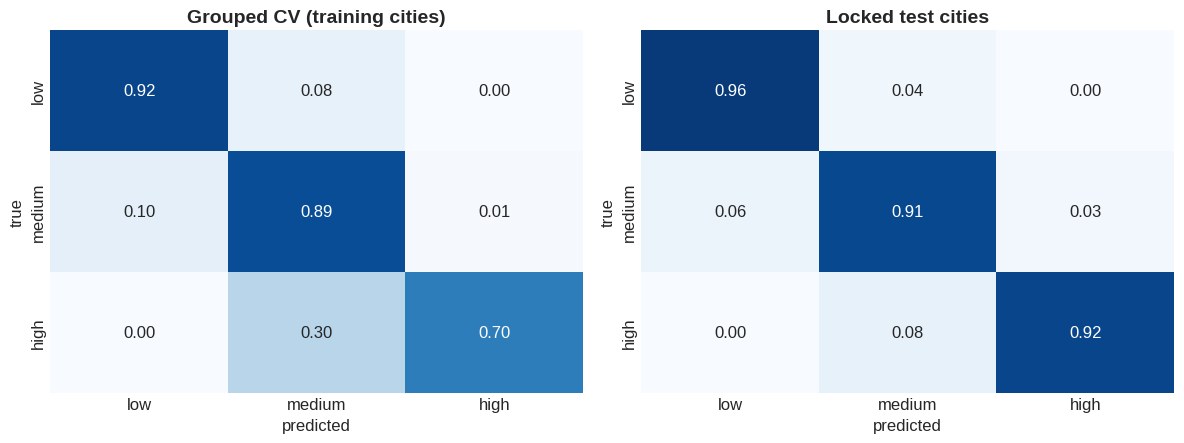

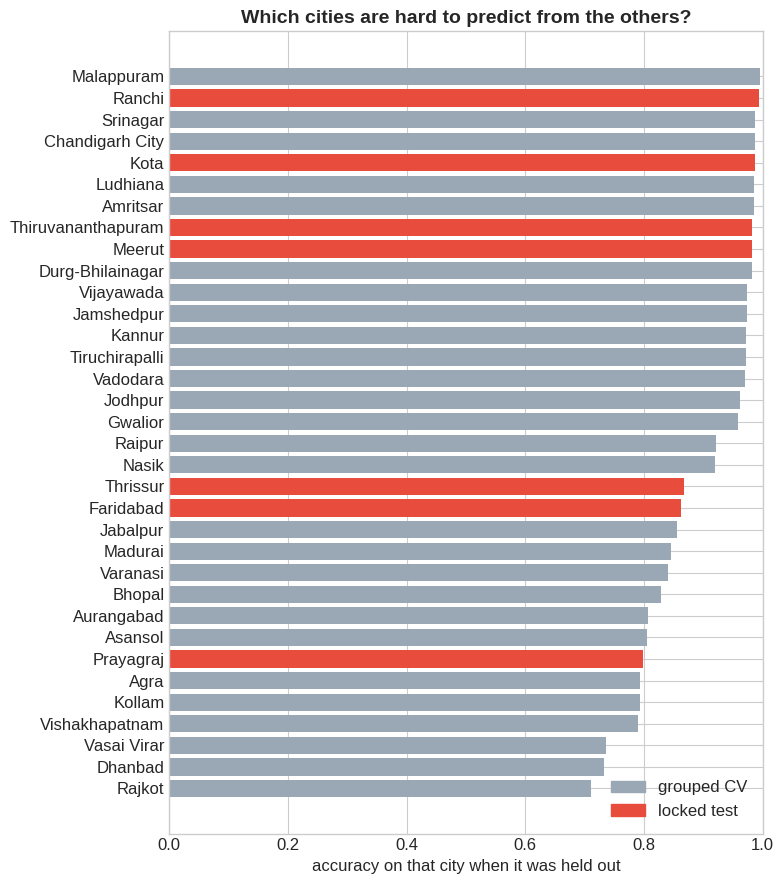

Hardest 5 cities: Rajkot (0.71), Dhanbad (0.73), Vasai Virar (0.74), Vishakhapatnam (0.79), Kollam (0.79)


In [125]:
# Confusion matrices (row-normalised) and per-city accuracy
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (yt, yp, title) in zip(axes, [(ytr_, oof_pred, 'Grouped CV (training cities)'),
                                      (y_u[te_idx], pred_te, 'Locked test cities')]):
    cm = confusion_matrix(yt, yp, labels=[0, 1, 2], normalize='true')
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=RISK_ORDER, yticklabels=RISK_ORDER)
    ax.set_title(title, fontweight='bold'); ax.set_xlabel('predicted'); ax.set_ylabel('true')
plt.tight_layout(); plt.show()

acc_city = pd.concat([
    pd.DataFrame({'city': gtr_, 'ok': (oof_pred == ytr_), 'split': 'train city (grouped CV)'}),
    pd.DataFrame({'city': g_u[te_idx], 'ok': (pred_te == y_u[te_idx]), 'split': 'locked test city'})])
acc_city = acc_city.groupby(['city', 'split']).ok.mean().reset_index().sort_values('ok')
fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(acc_city.city, acc_city.ok, color=acc_city.split.map({'train city (grouped CV)': '#9aa7b4', 'locked test city': '#e74c3c'}))
ax.set_xlim(0, 1); ax.set_xlabel('accuracy on that city when it was held out')
ax.set_title('Which cities are hard to predict from the others?', fontweight='bold')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='#9aa7b4', label='grouped CV'), Patch(color='#e74c3c', label='locked test')], loc='lower right')
plt.tight_layout(); plt.show()
print('Hardest 5 cities:', ', '.join(f'{c} ({a:.2f})' for c, a in acc_city.head(5)[['city', 'ok']].values))

## Which Features Matter? (Permutation Importance on Unseen Cities)

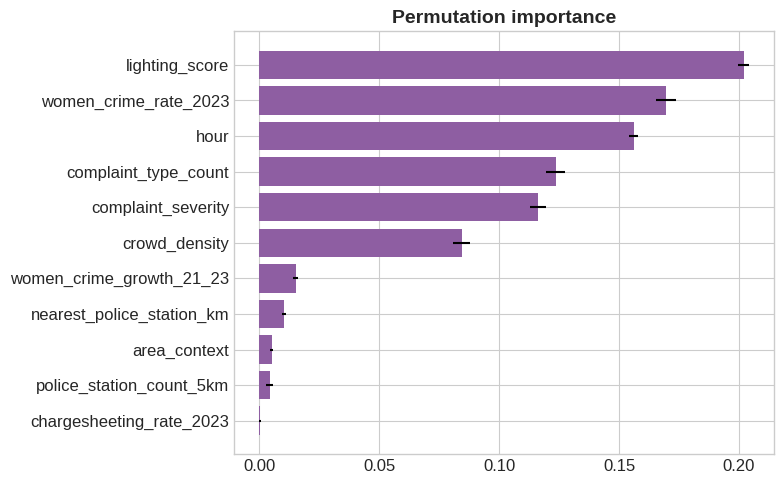

,mean,std
lighting_score,0.2020,0.0024
women_crime_rate_2023,0.1696,0.0043
hour,0.1560,0.0019
complaint_type_count,0.1235,0.0040
complaint_severity,0.1162,0.0033
crowd_density,0.0843,0.0034
women_crime_growth_21_23,0.0151,0.0011
nearest_police_station_km,0.0103,0.0008
area_context,0.0051,0.0006
police_station_count_5km,0.0043,0.0014


In [126]:
pi = permutation_importance(final, Xr.iloc[te_idx], y_u[te_idx], scoring='f1_macro', n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({'mean': pi.importances_mean, 'std': pi.importances_std}, index=FEATURES).sort_values('mean')
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp['mean'], xerr=imp['std'], color='#8e5ea2')
ax.set_title('Permutation importance', fontweight='bold'); plt.tight_layout(); plt.show()
display(imp.sort_values('mean', ascending=False).round(4))

### Feature Importance Results

* **Most important:** `lighting_score` (0.190 drop in macro F1 when shuffled), `women_crime_rate_2023` (0.150), `hour` (0.148), `complaint_severity` (0.120) and `complaint_type_count` (0.106), followed by `crowd_density` (0.069)
* **Small effect:** `women_crime_growth_21_23` (0.017), `nearest_police_station_km` (0.003), `area_context` (0.002) and `police_station_count_5km` (0.001)
* **No effect:** `chargesheeting_rate_2023` is slightly below zero (minus 0.0001), so shuffling it changes nothing

The model learns on two sources of information: the time and place pattern (`lighting_score`, `hour`, `crowd_density`) and how serious the city and the crime are (crime rate, severity and count). Because `lighting_score`, `crowd_density`, `hour` and `area_context` are all derived from the same area and hour grid, they share credit, and each one looks less important than the group does together.

The police features helped the cross-validated score in section 15 but matter little on the 7 test cities. That is another sign that city-level effects are hard to pin down with so few cities.

## Saving it as a joblib file to be used in an application, if possible


In [127]:
deploy = Pipeline([('prep', make_prep(FEATURES)),
                   ('model', xgb.XGBClassifier(**{**clf.get_params()}))])
deploy.fit(dfu[FEATURES], y_u, model__sample_weight=class_weights(y_u, WMODE))
joblib.dump(deploy, 'narisafe_risk_pipeline.joblib')

metadata = {
    'target': 'risk_level', 'classes_in_order': RISK_ORDER, 'features': FEATURES,
    'weighting': WMODE, 'xgb_params': {k: v for k, v in BEST.items() if k not in ('num_class', 'eval_metric')},
    'rounds': ROUNDS, 'locked_test_cities': test_cities,
    'metrics_grouped_cv': {k: float(v) for k, v in scores(ytr_, oof_pred).items()},
    'metrics_locked_test': {k: float(v) for k, v in scores(y_u[te_idx], pred_te).items()},
    'trained_on_rows': int(len(dfu)), 'trained_on_cities': int(dfu.city.nunique())
}
with open('narisafe_model_metadata.json', 'w') as f: json.dump(metadata, f, indent=2)

example = dfu[(dfu.city == 'Agra') & (dfu.hour == 23) & (dfu.area_context == 'transit')].iloc[[0]][FEATURES]
reloaded = joblib.load('narisafe_risk_pipeline.joblib')
print('example input:\n', example.T.to_string(), '\n')
print('predicted probabilities:', dict(zip(RISK_ORDER, reloaded.predict_proba(example)[0].round(3))))
print('saved: narisafe_risk_pipeline.joblib, narisafe_model_metadata.json')

example input:
                                1932
hour                             23
area_context                transit
crowd_density                medium
lighting_score                    2
complaint_severity                2
complaint_type_count              0
women_crime_rate_2023         128.1
chargesheeting_rate_2023       81.3
women_crime_growth_21_23    -0.0576
police_station_count_5km         16
nearest_police_station_km  0.752685 

predicted probabilities: {'low': np.float32(0.011), 'medium': np.float32(0.908), 'high': np.float32(0.08)}
saved: narisafe_risk_pipeline.joblib, narisafe_model_metadata.json


# Summary of the whole notebook

## What the data is
The csv file holds 489,804 rows and 40 columns for 34 Indian metropolitan cities. The crime columns (yearly counts, rate per lakh, chargesheeting rate, 42 crime heads) come from official NCRB city tables. The time, area, crowd and lighting columns are not observations: they are constructed. The rows form a full grid of city, weekday, hour, area type and crime type, and 28 of the 40 columns are constant within a city, so there are really only 34 city profiles.

## What the data exploration found
* The target is imbalanced: 58.8 percent medium, 36.3 percent low and 5.0 percent high.
* Time of day is the dominant pattern: 20.8 percent of late-night rows are high against 0.1 percent in the afternoon.
* Weekday has no effect at all. Every day has the same label mix.
* Industrial (16.1 percent) and transit (8.4 percent) areas carry the most high labels, and low crowd density goes with more high labels. Crowd density and lighting are lookups of area and hour.
* More serious crime heads receive more high labels (2.0, 5.4 and 8.6 percent for severity 1, 2 and 3).
* Cities differ widely, from 0.2 percent high in Madurai to 25.6 percent in Vasai Virar. Higher crime rates, greater distance to police and fewer education and commercial places go with higher risk.
* Many columns are redundant (twelve pairs correlate above 0.8), crime counts are heavily skewed (64.5 percent zeros), and street-light data exist for only 3 cities.

## What the structure checks revealed
The checks in section 13 showed that every distinct feature vector has exactly one label and that weekday changes nothing, so the 489,804 rows are 69,972 distinct vectors repeated seven times. On a random row split, the same city and identical rows appear on both sides, and identifiers such as city and coordinates let a model recognise the city. In section 14 that setup scores 1.000 on every metric, while the same model and features on unseen cities scores 0.886 accuracy and 0.63 recall on `high`. Random row splits therefore measure memorisation of city identity, not generalisation.

##Modelling approach
* Validation holds out whole cities: grouped cross-validation on 27 cities and 7 locked test cities.
* Identifiers, weekday columns, raw yearly counts and redundant columns are left out. The 11 remaining features were chosen by a city-held-out ablation and the one standard error rule.
* The model is a shallow, regularised XGBoost (depth 3, minimum child weight 20, 237 rounds), tuned only on training cities.
* Balanced class weights are used because they gave the best macro F1 and the best recall on the rare `high` class.
* The target keeps its order (low, medium, high), and ordinal metrics are reported alongside accuracy and macro F1.
* The preprocessing and model are saved together as one pipeline.

## Results

| Evaluation | Accuracy | Macro F1 | Recall (high) |
|---|---|---|---|
| Random row split (baseline) | 1.000 | 1.000 | 1.000 |
| Same features, unseen cities | 0.886 | 0.833 | 0.630 |
| Tuned model, grouped CV (unseen cities) | 0.889 | 0.855 | 0.824 |
| Tuned model, 7 locked test cities | 0.923 | 0.868 | 0.957 |

The grouped CV row is the most trustworthy because it uses all 27 training cities in turn. The locked test is a single draw of 7 cities and likely flattering, and its precision on `high` is only 0.590. The most important features on unseen cities are lighting score, crime rate, hour, severity, complaint count and crowd density.

## How to read these results
* The label is computed from the inputs, so the scores show how well a labelling rule is recovered on unseen cities. They do not show how well real-world risk is predicted.
* With only 34 cities, every city-level result rests on 34 data points, and scores can change noticeably with a different draw of test cities.
* The high class is rare and the hardest to get right, so recall and precision for it should always be reported.

## Saved files
`narisafe_risk_pipeline.joblib` (the full preprocessing and model pipeline) and `narisafe_model_metadata.json` (features, parameters, honest metrics and the warning about the label).